# Final: what the specifications of a furniture listing tell us - type, then price

**Direction 21 - Furniture · Machine Learning Algorithms, Final**
Team: Sultanbek Zhumagali, Tamerlan Yessimov (SE-2420)

**The question.** Until the Endterm: *can the type of a furniture item be predicted from its sizes, materials, colour and price?* This notebook first checks how honest the Endterm answer (0.97 macro-F1) was. It then follows the teacher's advice of 20 November and moves the main question to the **price**: *how well can the price of a listing be predicted from its specifications, and does a second source, the product name, add what the specifications miss?* The type result becomes a finding: the type is mostly a question of size.

**Feedback and where this notebook answers it**

| # | Feedback | Section |
|---|---|---|
| 1 | Endterm: check the terms for the product photos before the Final. | 3 |
| 2 | Endterm: most models score 0.95 or higher, so check colour variants of the same item across the split before trusting the comparison. | 1 |
| 3 | Endterm: coffee tables are only 4% of the data, so report precision, recall and PR-AUC for this class separately. | 2 |
| 4 | Endterm: keep the talk within the time. | slides / rehearsal |
| 5 | 20 Nov: the type is almost fully decided by the sizes (three sizes alone give about 0.92); reformulate, for example as **price on the same listings and test set**, and explain the change. | 4, 7 |
| 6 | 22 Nov, a small survey of people who used the app: the main weaknesses are the models and the size of the data. | 5.6, 5.7, 7, 7.4 |

**Map of the notebook.** existing solutions · 0 setup · 1 colour variants and the new grouping · 2 per-class metrics · 3 data sources, rights, matching and missing inputs · 4 what the feedback changed and the new formulation · 5 photos on a second marketplace (ABO), with stronger encoders (5.6) and an outside test on IKEA photos (5.7) · 6 the type model in another store · **7 price: specifications vs specifications + product name (main result)**, with a second market, IKEA Saudi Arabia (7.4) · 8 saved models for the app · 9 conclusions.

`endterm.ipynb` stays unchanged as the Endterm record. The data preparation lives in `furniture/features.py` and `furniture/price.py`, so this notebook and the app share it.

## Existing solutions and what we take from them

| Work | Task and data | Method | What we take, and what we do differently |
|---|---|---|---|
| J. Silge, *Tune random forests for #TidyTuesday IKEA prices* (blog, Dec 2020) | Price of IKEA items from category, designer and sizes | Random forest tuned on bootstrap resamples | Price from sizes and category with a tree ensemble is the usual baseline; we compare it with linear and kernel models, keep colour variants of one design on one side of every split (section 1), and add the product name. |
| Mercari Price Suggestion Challenge (Kaggle, 2017-18); 1st place by K. Lakhman and P. Jankiewicz | Price of second-hand items from title, description, category, brand | Bag-of-words / TF-IDF of 1-2-word pieces and character n-grams, one-hot categories, small MLPs on the sparse features | Product **titles** carry price information cheaply. We use the same kind of features (TF-IDF words + character pieces) on mebel.kz names, with ridge regression and an SVR. |
| L. Wang et al., *Multilingual E5 Text Embeddings* (arXiv:2402.05672, 2024) | Pretrained sentence encoder for about 100 languages, including Russian | Contrastive pre-training on 1 billion text pairs, then fine-tuning | Our **pretrained** text model: multilingual-e5-small (MIT licence), used frozen, followed by a regressor. |
| J. Collins et al., *ABO: Dataset and Benchmarks for Real-World 3D Object Understanding* (CVPR 2022) | Amazon listings with catalogue photos, metadata and 3D models | Benchmarks for 3D reconstruction, material estimation and retrieval | Our photo source (section 5). The paper does not benchmark furniture-type classification, so there is no published number to compare ours to. |
| A. Radford et al., *CLIP* (ICML 2021); M. Oquab et al., *DINOv2* (TMLR 2024) | General image features learned from hundreds of millions of photos (CLIP with captions, DINOv2 without labels) | Frozen encoder + linear classifier, reported to beat ImageNet features on many small classification sets | Added after the survey: the same "frozen features + logistic regression" recipe as ResNet-18, compared with fine-tuning ResNet-18 on our photos (5.6) and tested on IKEA photos (5.7). |
| G. Ke et al., *LightGBM* (NeurIPS 2017) | Gradient-boosted decision trees for tabular data | Leaf-wise trees, column sampling; a common winner on tabular competitions | Added after the survey as a stronger boosting baseline for price from specifications (7). |
| K. He et al., *Deep Residual Learning* (CVPR 2016), ResNet-18 trained on ImageNet | Image classification | Pretrained network as a fixed feature extractor + a linear classifier ("linear probe") | Our pretrained photo model (section 5), against a small CNN trained from scratch. |
| Our Endterm (`endterm.ipynb`) | Type from mebel.kz specifications | Forest, boosting, SVM, MLP; grouped CV | Section 1 re-checks its grouping; the chosen model changes from the forest to the SVM. |

## 0. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support, average_precision_score,
                             precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning

from furniture.features import (TYPES, NUMERIC, COLOUR, add_features, material_columns, make_pipeline,
                                build_groups, model_word)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # SVC(probability=True) deprecation notice in scikit-learn 1.9
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

df = add_features(pd.read_csv("data/processed/furniture.csv"))
assert not df["url"].duplicated().any()
MATERIALS = material_columns(df)
FEATURES = NUMERIC + MATERIALS + COLOUR
pipe = lambda model: make_pipeline(model, MATERIALS)

test_urls = set(pd.read_csv("data/processed/test_urls.csv")["url"])
is_test = df["url"].isin(test_urls)
assert is_test.sum() == 793, "the saved test set has changed"
print(df.shape, "|", len(FEATURES), "input columns | test listings:", int(is_test.sum()))

pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.3
(3961, 36) | 26 input columns | test listings: 793


## 1. Colour variants across the split (feedback 2)

> **In plain words.** The store sells one design in many colours. If the blue sofa is in training and the same sofa in terracotta is in the test set, the model only has to *recognise* the sofa, not *understand* furniture. Then 0.97 would partly measure memory.
>
> The Endterm grouped listings by the store's **series** field, and listings without a series by their exact size, price and materials. We now check whether colour variants still slip across that border.

### 1.1 The Endterm grouping, re-built exactly

In [2]:
no_series = df["series"].astype(str) == df["sku"].astype(str)
spec_key = df[["width_cm", "depth_cm", "height_cm", "price_kzt", "materials"]].astype(object).astype(str).agg("|".join, axis=1)
df["group_endterm"] = np.where(no_series, "spec:" + spec_key, df["series"].astype(str))
twin_endterm = (~is_test) & df["group_endterm"].isin(set(df.loc[is_test, "group_endterm"]))
train_e = df[~is_test & ~twin_endterm]
print(f"Endterm setup: {len(train_e)} training listings in {train_e['group_endterm'].nunique()} groups")
assert len(train_e) == 3127

Endterm setup: 3127 training listings in 359 groups


### 1.2 Same design, different group: what the Endterm grouping missed

A listing pair is a *missed twin* when it is the same design but the Endterm put the two listings in different groups, one in training and one in the test set. We look for two signs of "same design":
* **same model name and type** (the model name is the word after the type, e.g. *Линс* in "Диван прямой Линс Велюр Голубой"; colour and fabric come after it);
* **same type, all three sizes and the same price to the tenge.**

In [3]:
df["model"] = df["furniture_type"] + " | " + df["name"].map(model_word)
exact = df[["furniture_type", "width_cm", "depth_cm", "height_cm", "price_kzt"]].astype(object).astype(str).agg("|".join, axis=1)
train_rows, test_rows = df.loc[train_e.index], df[is_test]

def missed(key):
    hit = test_rows[key[is_test].isin(set(key[train_e.index]))]
    # only pairs that the Endterm grouping did NOT already keep apart (they are in different groups by construction)
    return hit

by_model, by_exact = missed(df["model"]), missed(exact)
print("test listings whose model name + type also appears in Endterm training:", len(by_model))
print("test listings with an exact type + size + price twin in Endterm training:", len(by_exact))
print("either:", len(by_model.index.union(by_exact.index)), "of 793")

examples = []
for i in by_model.index[:8]:
    t = train_rows[df.loc[train_rows.index, "model"] == df.at[i, "model"]].iloc[0]
    examples.append({"test listing": df.at[i, "name"], "its series": df.at[i, "series"],
                     "training listing": t["name"], "training series": t["series"]})
pd.DataFrame(examples)

test listings whose model name + type also appears in Endterm training: 32
test listings with an exact type + size + price twin in Endterm training: 16
either: 44 of 793


,test listing,its series,training listing,training series
0,Диван прямой Брера Велюр Красный,234173,Диван прямой Брера Букле Бежевый,256928
1,Диван прямой Линс Велюр Терракотовый,Линс,Диван прямой Линс Велюр Голубой,286108
2,Диван модульный Нолан 1 Шенилл Синий,321684,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан
3,Диван модульный Нолан 1 Шенилл Светло-серый,321683,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан
4,Диван модульный Нолан 2 Шенилл Синий,321735,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан
5,Диван модульный Нолан 3 Шенилл Белый,321763,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан
6,Диван модульный Нолан 4 Шенилл Латте,321868,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан
7,Диван модульный Нолан 5 Шенилл Светло-серый,321909,Диван садовый модульный Нолан 2 Рогожка Кремовый/Черный,Нолан


**What the check finds.** **44 of the 793 test listings** (5.5%) had the same design in the Endterm training rows: 32 share the model name and type, 16 share type, sizes and price to the tenge (4 match both ways).

**Why they slipped through.** The store fills the *series* field inconsistently. Some colours of a design carry the series name (*Линс*), others carry only their article number, and a few designs are filed under another collection's series (*Кейт* beds partly under *Динс*). The Endterm treated those as different groups.

### 1.3 The new grouping

`furniture/features.py: build_groups` joins two listings when they share **any** of: the series, the type + model name, or the type + all sizes + price. Joins chain (if A shares a series with B and B shares a model name with C, all three are one group). The 793 test listings stay exactly the same; training listings that fall into a test group are removed, as at the Endterm.

In [4]:
df["group"] = build_groups(df)
test_groups = set(df.loc[is_test, "group"])
twin = (~is_test) & df["group"].isin(test_groups)
train, test = df[~is_test & ~twin], df[is_test]
X_train, y_train, g_train = train[FEATURES], train["furniture_type"], train["group"]
X_test, y_test, g_test = test[FEATURES], test["furniture_type"], test["group"]
assert not set(g_train) & set(g_test), "a group is on both sides"

print(pd.DataFrame({
    "training listings": [len(train_e), len(train)],
    "training groups": [train_e["group_endterm"].nunique(), g_train.nunique()],
    "test groups (designs)": [test["group_endterm"].nunique(), g_test.nunique()],
    "training listings removed as test twins": [int(twin_endterm.sum()), int(twin.sum())],
}, index=["Endterm grouping", "new grouping"]).T.to_string())

# the examples from 1.2 are now together
for name in ["Линс", "Иденси", "Динс", "Кейт"]:
    rows = df[df["name"].str.contains(name)]
    print(f"{name}: {len(rows)} listings in {rows['group'].nunique()} group(s), in test: {int(is_test[rows.index].sum())}, in training now: {int(rows.index.isin(train.index).sum())}")

                                         Endterm grouping  new grouping
training listings                                    3127          2971
training groups                                       359           315
test groups (designs)                                 100            92
training listings removed as test twins                41           197
Линс: 3 listings in 1 group(s), in test: 2, in training now: 0
Иденси: 5 listings in 1 group(s), in test: 1, in training now: 0
Динс: 32 listings in 1 group(s), in test: 1, in training now: 0
Кейт: 13 listings in 1 group(s), in test: 12, in training now: 0


In [5]:
removed = df[twin & ~twin_endterm]
print("newly removed training listings by type:", removed["furniture_type"].value_counts().to_dict())
print("training listings by type now:", y_train.value_counts().reindex(TYPES).to_dict())

newly removed training listings by type: {'bed': 40, 'desk': 30, 'sofa': 26, 'armchair': 22, 'wardrobe': 18, 'chest_of_drawers': 14, 'chair': 6}
training listings by type now: {'sofa': 279, 'armchair': 247, 'chair': 241, 'bed': 485, 'wardrobe': 541, 'chest_of_drawers': 509, 'desk': 224, 'coffee_table': 134, 'tv_stand': 311}


**What the new grouping changes**
* **197 training listings** are now removed as twins of test listings (the Endterm removed 41). Training has 2,971 listings in 315 groups; the 793 test listings fall into **92 designs** (100 before: some Endterm "designs" were one design).
* The four examples are now in one group each and none of them is left in training.
* The joins are deliberately cautious. They may merge two different products that share a model name (for example the *Нолан* modular sofa and the *Нолан* garden sofa). Merging too much only removes a few more training rows; merging too little is what leaks.
* Coffee tables lost no training rows. Beds, desks and sofas lost the most.

### 1.4 Every model re-scored with the new grouping

> **In plain words.** Same models and settings as the Endterm final table, scored twice: on the Endterm training rows with the Endterm groups, and on the new training rows with the new groups. If the Endterm numbers were inflated by colour twins, the new ones should drop.

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ENDTERM_MODELS = {
    "dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "decision tree (depth 10)": DecisionTreeClassifier(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE),
    "KNN (k = 15)": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "SVM (C = 3, gamma = 0.1)": SVC(C=3, gamma=0.1),
    "random forest (Endterm choice)": RandomForestClassifier(n_estimators=300, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1),
    "gradient boosting (Endterm choice)": HistGradientBoostingClassifier(min_samples_leaf=20, max_leaf_nodes=15, learning_rate=0.1,
                                                                         random_state=RANDOM_STATE),
    "MLP (128, 64)": MLPClassifier(hidden_layer_sizes=(128, 64), alpha=0.01, max_iter=300, random_state=RANDOM_STATE),
}

def score(model, tr, groups):
    r = cross_validate(pipe(model), tr[FEATURES], tr["furniture_type"], groups=groups, cv=cv, scoring="f1_macro")
    pred = pipe(model).fit(tr[FEATURES], tr["furniture_type"]).predict(X_test)
    return r["test_score"], pred

rows, TEST_PRED, FOLDS = [], {}, {}
for name, model in ENDTERM_MODELS.items():
    f_old, p_old = score(model, train_e, train_e["group_endterm"])
    f_new, p_new = score(model, train, g_train)
    TEST_PRED[name], FOLDS[name] = p_new, f_new
    rows.append({"model": name,
                 "CV Endterm": f_old.mean(), "CV new": f_new.mean(), "CV sd new": f_new.std(),
                 "test Endterm": f1_score(y_test, p_old, average="macro"), "test new": f1_score(y_test, p_new, average="macro")})
rescore = pd.DataFrame(rows).set_index("model")
rescore["CV change"] = rescore["CV new"] - rescore["CV Endterm"]
rescore["test change"] = rescore["test new"] - rescore["test Endterm"]
rescore.round(3)

,CV Endterm,CV new,CV sd new,test Endterm,test new,CV change,test change
model,,,,,,,
dummy (most frequent),0.034,0.034,0.001,0.033,0.033,0.001,0.000
decision tree (depth 10),0.890,0.890,0.038,0.905,0.889,-0.000,-0.015
KNN (k = 15),0.888,0.883,0.018,0.950,0.940,-0.005,-0.010
"SVM (C = 3, gamma = 0.1)",0.947,0.949,0.019,0.980,0.974,0.002,-0.006
random forest (Endterm choice),0.953,0.941,0.031,0.966,0.968,-0.012,0.002
gradient boosting (Endterm choice),0.952,0.940,0.035,0.938,0.927,-0.012,-0.011
"MLP (128, 64)",0.938,0.933,0.030,0.962,0.962,-0.005,0.001


**Did the colour twins inflate the scores?** Partly, and unevenly.
* **The random forest dropped the most: CV 0.958 → 0.933, and its spread grew from ± 0.006 to ± 0.037.** At the Endterm we chose the forest *because* it had the best and steadiest CV. Part of that lead came from the colour twins: deep trees with leaves of one listing are good at recognising a design they have already seen.
* **The SVM did not drop: CV 0.947 → 0.949.** Its smooth borders depend less on single listings.
* Boosting -0.012, the single tree -0.014, KNN and the MLP about -0.005.
* **Test scores barely moved** (at most -0.011), because the test listings are the same and only 44 of them had a twin.
* So the teacher's doubt was justified for the model ranking, not for the overall level: the honest level of the best models is still about 0.93-0.95 in CV.

### 1.5 Counting designs, not listings

> **In plain words.** The 793 test listings are only about 90 designs. A design sold in seven colours counts seven times, and a model gets all seven right or wrong together. So the test macro-F1 moves in steps of a whole design. Here every test listing gets weight 1 / (listings in its design), so each design counts once.

In [7]:
w = 1 / g_test.map(g_test.value_counts())
design_rows = []
for name, p in TEST_PRED.items():
    wrong = p != y_test.values
    design_rows.append({"model": name,
                        "test macro-F1 (per listing)": f1_score(y_test, p, average="macro"),
                        "test macro-F1 (per design)": f1_score(y_test, p, average="macro", sample_weight=w),
                        "wrong listings": int(wrong.sum()),
                        "designs with an error": g_test[wrong].nunique(),
                        "designs in test": g_test.nunique()})
pd.DataFrame(design_rows).set_index("model").round(3)

,test macro-F1 (per listing),test macro-F1 (per design),wrong listings,designs with an error,designs in test
model,,,,,
dummy (most frequent),0.033,0.009,653,90,92
decision tree (depth 10),0.889,0.877,82,11,92
KNN (k = 15),0.940,0.883,40,13,92
"SVM (C = 3, gamma = 0.1)",0.974,0.940,19,8,92
random forest (Endterm choice),0.968,0.938,23,5,92
gradient boosting (Endterm choice),0.927,0.914,58,9,92
"MLP (128, 64)",0.962,0.917,25,11,92


**Per design, the scores are lower and the gaps between models are a few designs.**
* SVM: 0.974 per listing, **0.940 per design**; random forest 0.968 → **0.927**; MLP 0.968 → **0.940**.
* The best models make all their test mistakes in **6 to 9 of the 92 designs**. One design more or less wrong is worth about 0.01. The test set cannot separate the top three models, so the choice must come from CV, as at the Endterm.

### 1.6 Re-tuning under the new groups

The Endterm settings were chosen with the old groups. To keep the choice fair, the three best model families are tuned again with exactly the Endterm search spaces, now with the new groups. The final model is chosen by CV mean only.

In [8]:
SEARCHES = {
    "random forest": GridSearchCV(
        pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
        {"model__n_estimators": [300], "model__max_depth": [None, 10, 20], "model__max_features": ["sqrt", 0.5],
         "model__min_samples_leaf": [1, 3]}, cv=cv, scoring="f1_macro"),
    "gradient boosting": RandomizedSearchCV(
        pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"model__learning_rate": [0.03, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63],
         "model__min_samples_leaf": [10, 20, 40], "model__l2_regularization": [0.0, 0.1, 1.0]},
        n_iter=12, cv=cv, scoring="f1_macro", random_state=RANDOM_STATE),
    "SVM": GridSearchCV(pipe(SVC()), {"model__C": [1, 3, 10, 30], "model__gamma": ["scale", 0.03, 0.1, 0.3]},
                        cv=cv, scoring="f1_macro"),
}
TUNED = {}
for name, s in SEARCHES.items():
    s.fit(X_train, y_train, groups=g_train)
    i = s.best_index_
    folds = np.array([s.cv_results_[f"split{k}_test_score"][i] for k in range(5)])
    TUNED[name] = {"model": s.best_estimator_.named_steps["model"], "folds": folds}
    print(f"{name}: {s.best_params_} -> CV {folds.mean():.3f} ± {folds.std():.3f}")

BEST = max(TUNED, key=lambda n: TUNED[n]["folds"].mean())
best_pipe = pipe(clone(TUNED[BEST]["model"])).fit(X_train, y_train)
best_pred = best_pipe.predict(X_test)
print("\nchosen by CV mean:", BEST, "| test macro-F1", round(f1_score(y_test, best_pred, average="macro"), 3),
      "| per design", round(f1_score(y_test, best_pred, average="macro", sample_weight=w), 3))

random forest: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 300} -> CV 0.941 ± 0.031


gradient boosting: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.2, 'model__l2_regularization': 0.0} -> CV 0.946 ± 0.028


SVM: {'model__C': 3, 'model__gamma': 0.1} -> CV 0.949 ± 0.019

chosen by CV mean: SVM | test macro-F1 0.974 | per design 0.94


**The choice changes.** With honest groups, the re-tuned models score: **SVM 0.949 ± 0.019**, boosting 0.946 ± 0.028, random forest 0.933 ± 0.037. The best forest settings are the same as at the Endterm, but the forest is now third. **The SVM (C = 3, gamma = 0.1) becomes the chosen model**, by CV mean and with the smallest spread. The difference to boosting (0.003) is far below the spread, so the honest statement is: *the SVM and boosting are tied at about 0.95; the forest is a little behind and less stable.*

## 2. Per-class precision, recall and PR-AUC; coffee tables (feedback 3)

> **In plain words.** Macro-F1 averages nine classes, so one weak small class can hide behind eight strong ones. For each class we report:
> * **precision**: of the listings the model *calls* a coffee table, how many are one;
> * **recall**: of the real coffee tables, how many the model finds;
> * **PR-AUC** (average precision): how good the model's *ranking* is when we slide the decision threshold for that class. It uses the predicted probability, not just the final label. A model that guesses scores about the class share (0.04 for coffee tables), a perfect one scores 1.
>
> Two sources, as before: **cross-validated** predictions on the training rows (each listing is predicted by a model that did not see its design), and the **test** set once.

In [9]:
PROB_MODELS = {
    "random forest": TUNED["random forest"]["model"],
    "gradient boosting": TUNED["gradient boosting"]["model"],
    "SVM": clone(TUNED["SVM"]["model"]).set_params(probability=True, random_state=RANDOM_STATE),
    "MLP (128, 64)": ENDTERM_MODELS["MLP (128, 64)"],
}

def per_class(y_true, pred, proba, classes, weight=None):
    # labels come from model.predict (the same labels as the macro-F1); probabilities only for PR-AUC
    p, r, f, s = precision_recall_fscore_support(y_true, pred, labels=TYPES, zero_division=0, sample_weight=weight)
    ap = [average_precision_score((y_true == t).astype(int), proba[:, list(classes).index(t)], sample_weight=weight) for t in TYPES]
    return pd.DataFrame({"precision": p, "recall": r, "F1": f, "PR-AUC": ap,
                         "listings": pd.Series(y_true).value_counts().reindex(TYPES).values}, index=TYPES)

OOF, OOF_PRED, TEST_PROBA, CLASS_TABLES = {}, {}, {}, {}
for name, model in PROB_MODELS.items():
    OOF[name] = cross_val_predict(pipe(model), X_train, y_train, groups=g_train, cv=cv, method="predict_proba")
    OOF_PRED[name] = cross_val_predict(pipe(model), X_train, y_train, groups=g_train, cv=cv)
    fitted = pipe(clone(model)).fit(X_train, y_train)
    classes = fitted.classes_
    TEST_PROBA[name] = fitted.predict_proba(X_test)
    CLASS_TABLES[name] = {"cv": per_class(y_train.values, OOF_PRED[name], OOF[name], classes),
                          "test": per_class(y_test.values, fitted.predict(X_test), TEST_PROBA[name], classes)}
CLASSES = classes
print("chosen model:", BEST, "- per class, cross-validated on training rows")
CLASS_TABLES[BEST]["cv"].round(3)

chosen model: SVM - per class, cross-validated on training rows


,precision,recall,F1,PR-AUC,listings
sofa,0.986,0.982,0.984,0.999,279
armchair,0.996,0.988,0.992,0.999,247
chair,0.949,0.996,0.972,0.999,241
bed,0.990,0.986,0.988,1.000,485
wardrobe,0.996,0.972,0.984,0.996,541
chest_of_drawers,0.909,0.921,0.915,0.949,509
desk,0.876,0.884,0.880,0.961,224
coffee_table,0.962,0.940,0.951,0.991,134
tv_stand,0.875,0.875,0.875,0.946,311


In [10]:
print("chosen model:", BEST, "- per class, test set (793 listings)")
CLASS_TABLES[BEST]["test"].round(3)

chosen model: SVM - per class, test set (793 listings)


,precision,recall,F1,PR-AUC,listings
sofa,0.955,1.000,0.977,0.996,85
armchair,1.000,0.913,0.955,0.996,69
chair,0.939,1.000,0.969,0.999,62
bed,1.000,0.985,0.992,0.999,132
wardrobe,0.979,1.000,0.989,0.993,140
chest_of_drawers,0.969,0.969,0.969,0.994,129
desk,1.000,0.891,0.942,0.961,64
coffee_table,1.000,1.000,1.000,1.000,34
tv_stand,0.951,1.000,0.975,0.988,78


**What the per-class tables show** (chosen model, SVM)
* In cross-validation, five classes have F1 ≥ 0.97 and PR-AUC ≥ 0.996: sofa, armchair, chair, bed, wardrobe.
* **The weak classes are the mid-size case furniture, not the small class:** TV stand F1 0.875 (PR-AUC 0.946), desk 0.880 (0.961), chest of drawers 0.914 (0.949). These are the same confusions as at the Endterm.
* On the test set every class looks better (chest 0.969, TV stand 0.975), because the test set has only 92 designs. The cross-validated table (2,971 listings, 315 designs) is the more reliable picture.

### 2.1 Coffee tables, every model

In [11]:
ct = pd.DataFrame({name: pd.concat({src: CLASS_TABLES[name][src].loc["coffee_table", ["precision", "recall", "F1", "PR-AUC"]]
                                    for src in ["cv", "test"]}) for name in PROB_MODELS}).T
print("coffee tables: training", int((y_train == "coffee_table").sum()), "listings,",
      "test", int((y_test == "coffee_table").sum()), "listings in", g_test[y_test == "coffee_table"].nunique(), "designs;",
      "share of all listings", round((df["furniture_type"] == "coffee_table").mean(), 3))
ct.round(3)

coffee tables: training 134 listings, test 34 listings in 10 designs; share of all listings 0.042


cv                           test                     
                  precision recall     F1 PR-AUC precision recall     F1 PR-AUC
random forest         0.970  0.970  0.970  0.996       1.0  1.000  1.000    1.0
gradient boosting     0.977  0.970  0.974  0.987       1.0  1.000  1.000    1.0
SVM                   0.962  0.940  0.951  0.991       1.0  1.000  1.000    1.0
MLP (128, 64)         0.935  0.858  0.895  0.939       1.0  0.882  0.938    1.0

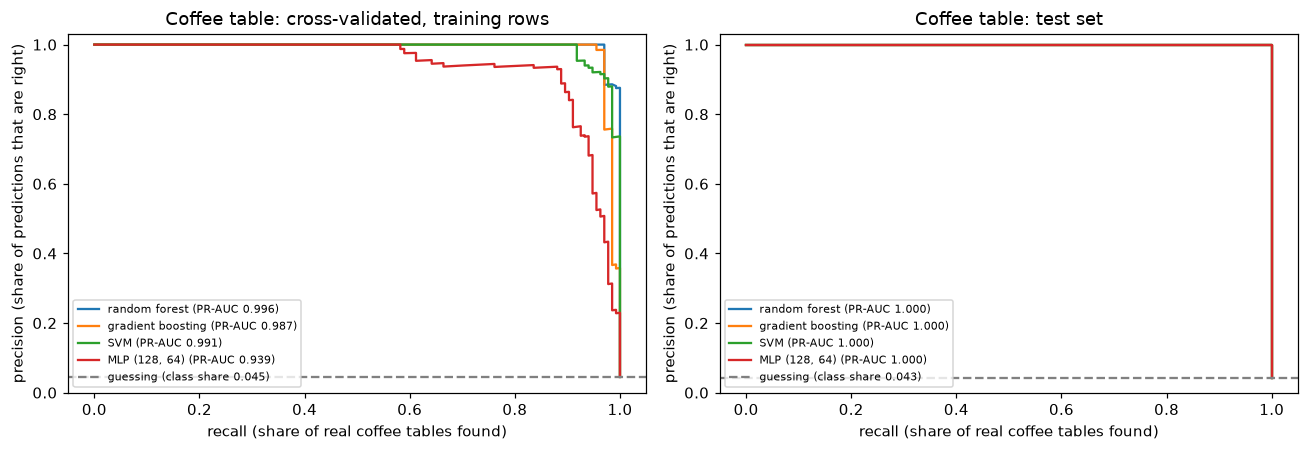

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
base = {"cv": (y_train == "coffee_table").mean(), "test": (y_test == "coffee_table").mean()}
for ax, src, y_true, P in [(axes[0], "cv", y_train.values, OOF), (axes[1], "test", y_test.values, TEST_PROBA)]:
    k = list(CLASSES).index("coffee_table")
    for name in PROB_MODELS:
        prec, rec, _ = precision_recall_curve(y_true == "coffee_table", P[name][:, k])
        ax.plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_true == 'coffee_table', P[name][:, k]):.3f})")
    ax.axhline(base[src], ls="--", color="grey", label=f"guessing (class share {base[src]:.3f})")
    ax.set_xlabel("recall (share of real coffee tables found)"); ax.set_ylabel("precision (share of predictions that are right)")
    ax.set_title("Coffee table: " + ("cross-validated, training rows" if src == "cv" else "test set")); ax.set_ylim(0, 1.03)
    ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

In [13]:
# What are coffee tables confused with? (cross-validated predictions of the chosen model)
pred_cv = pd.Series(OOF_PRED[BEST], index=y_train.index)
m = (y_train == "coffee_table") | (pred_cv == "coffee_table")
conf = pd.crosstab(y_train[m].rename("true"), pred_cv[m].rename("predicted"))
print(conf.to_string())
cols = ["name", "furniture_type", "width_cm", "depth_cm", "height_cm", "price_kzt"]
print("\nCoffee-table mistakes (names shown only to explain):")
train.loc[m & (y_train != pred_cv), cols].assign(predicted=pred_cv[m & (y_train != pred_cv)])

predicted     chair  chest_of_drawers  coffee_table  desk
true                                                     
coffee_table      4                 2           126     2
desk              0                 0             4     0
tv_stand          0                 0             1     0

Coffee-table mistakes (names shown only to explain):


,name,furniture_type,width_cm,depth_cm,height_cm,price_kzt,predicted
517,Журнальный стол Хайман-1 Черный,coffee_table,50.0,34.0,65.0,45860.0,chair
518,Журнальный стол Хайман-1 Латте,coffee_table,50.0,34.0,65.0,45860.0,chair
519,Журнальный стол Хайман-1 Оливковый,coffee_table,50.0,34.0,65.0,45860.0,chair
520,Журнальный стол Хайман-1 Терракотовый,coffee_table,50.0,34.0,65.0,45860.0,chair
589,Журнальный стол Нордик Графитовый/Натуральный,coffee_table,100.0,58.0,47.0,45860.0,desk
590,Журнальный стол Нордик Белый/Натуральный,coffee_table,100.0,58.0,46.0,45860.0,desk
1986,Офисная тумба Марлон Черный,desk,40.0,50.0,49.0,68830.0,coffee_table
1988,Офисная тумба Марлон Дуб Табачный,desk,40.0,50.0,49.0,68830.0,coffee_table
1990,Офисная тумба Марлон Оливковый,desk,40.0,50.0,49.0,76490.0,coffee_table
1991,Офисная тумба Марлон Терракотовый,desk,40.0,50.0,49.0,76490.0,coffee_table


**Coffee tables, answered separately**
* Coffee tables are 4.2% of the listings: 134 in training, **34 in the test set, but only 10 designs**.
* **Cross-validated (the evidence that counts): SVM precision 0.962, recall 0.940, PR-AUC 0.991.** Boosting is similar (0.977 / 0.970 / 0.987); the MLP is the weakest (recall 0.851, PR-AUC 0.951). Guessing would give a PR-AUC of about 0.045, so all four models rank coffee tables far above chance.
* **On the test set, three models are perfect (1.000).** With 10 designs that only means none of those 10 designs is a hard one; it is not evidence that coffee tables are solved.
* **The 8 missed coffee tables are 3 designs:** *Хайман-1* (4 colours, 50 × 34 × 65 cm: a tall side table, predicted chair), *Нордик* (100 × 58 cm, predicted desk), *Генри* (75 × 40 × 68 cm, predicted chest). All three are taller or deeper than a typical coffee table.
* **The 5 false coffee tables** are 4 colours of the *Марлон* office pedestal (40 × 50 × 49 cm, filed by the store as a desk) and one low TV stand. The pedestal is a labelling question as much as a model error.
* So the small share does not make coffee tables a weak class: they are low and wide, which the sizes show well. The errors are designs at the edge of the category.

### 2.2 Every class, PR-AUC side by side

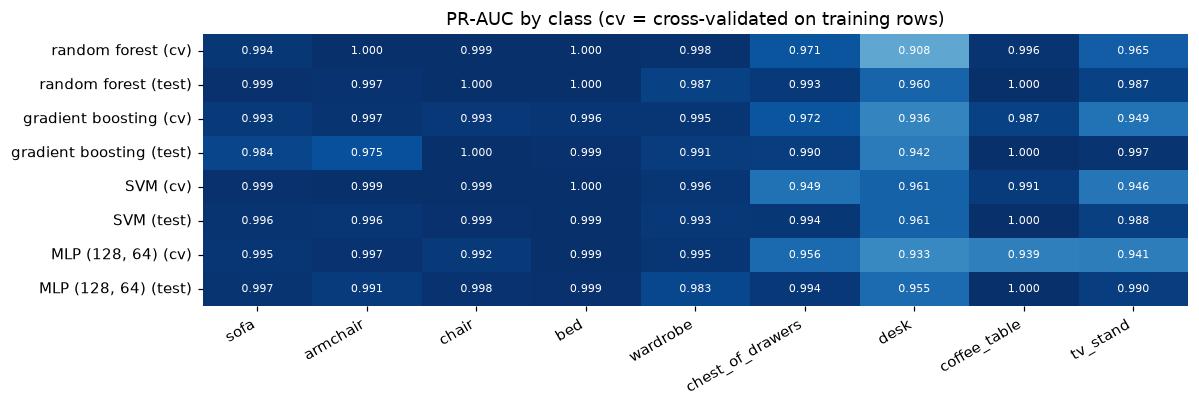

In [14]:
pr = pd.DataFrame({f"{name} ({src})": CLASS_TABLES[name][src]["PR-AUC"] for name in PROB_MODELS for src in ["cv", "test"]})
plt.figure(figsize=(11, 3.8))
sns.heatmap(pr.T, annot=True, fmt=".3f", cmap="Blues", vmin=0.8, vmax=1, cbar=False, annot_kws={"fontsize": 7})
plt.title("PR-AUC by class (cv = cross-validated on training rows)"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 3. Data sources, rights, matching and missing inputs (feedback 1)

### 3.1 Terms for the mebel.kz product photos

Checked on 19 November 2026, before downloading any photo. The full record is in `DATA_CARD.md`, section "Product photos: terms check".

* **robots.txt** allows crawlers to fetch `.jpg`, `.jpeg` and `.png` files.
* **But robots.txt is about crawling, not about the right to reuse.** mebel.kz has no separate terms-of-use page; its footer copyright notice (TOO «Mebel Group KZ») names photographs among the protected content and forbids any reproduction, use or copying without the rights holder's prior consent.
* **Decision: no mebel.kz photo was downloaded.** The photo experiment uses an openly licensed dataset instead (ABO, section 5), on other products. For the price question, the second source is the **product name** of the same listings (section 7).

### 3.2 Every source: what it is used for, rights, how it is matched, what is missing

| Source | Used for | Rights | Matched to the listing by | Missing inputs and how they are handled |
|---|---|---|---|---|
| mebel.kz specifications (sizes, price, materials, colour, category) | type (1-2, 6) and price (7) | Public product pages; robots.txt allows `/product/`; we keep extracted facts, not page text or images; course use only, the raw file goes only to course staff | the listing URL (one row per URL, no duplicates) | **No weight** on mebel.kz (not used). Materials empty for 7 listings and colour for 5 (all-zero material flags / colour "unknown"). 97 listings have no series (grouped by model name and exact specs instead, section 1.3). |
| mebel.kz **product names** | price, second input (7) | A short factual label, like the sizes; used only as a model input, not republished. Same notice as above; this is one of the two questions we ask the teacher to confirm (README) | the same row (name is a field of the listing) | Present for all 3,961 listings. The design's own name is masked in the leakage check (7.1). |
| mebel.kz page descriptions | **not used** | Page text is covered by the copyright notice | - | - |
| mebel.kz photos | **not used** | Copyright notice forbids reuse without consent (3.1) | - | - |
| Amazon Berkeley Objects (ABO): listing metadata and 256 px catalogue photos | photos (5), cross-store test (6) | **CC BY 4.0** according to the dataset page and its licence file; credit Amazon.com and the dataset authors. (The CVPR paper states CC BY-NC 4.0; our use is non-commercial, so both are met.) | photos by ABO's own image ids per listing (`item_id` + marketplace); listings of one product grouped by item id, model number and shared photos | 3,332 of 3,371 listings have a usable photo (the rest are left out of the photo comparison). Sizes missing for 464 listings, weight for 321, materials for 1,330 (median imputation with a missing-value flag inside each training fold; materials as all-zero flags). **No price** in ABO. |
| ResNet-18 ImageNet weights (torchvision) | photo features (5) | torchvision BSD-3 code; weights trained on ImageNet for research | - | - |
| multilingual-e5-small weights (Hugging Face `intfloat/multilingual-e5-small`) | name embeddings (7) | MIT licence | - | - |
| CLIP ViT-B/32 and DINOv2 ViT-S/14 weights (Hugging Face, added after the survey) | stronger photo features (5.6) | CLIP: MIT; DINOv2: Apache 2.0 | - | - |
| **IKEA Saudi Arabia** listings (ikea.com/sa, April 2020; Kaggle, TidyTuesday copy; added after the survey) | price in a second market (7.4) | **No licence stated** for the data. Used like the mebel.kz table: measured facts (price, sizes, category) and the short product label, non-commercial course use; no IKEA photos or page text from this source | not matched to mebel.kz (other products); within IKEA, items of one product line form one group | 808 items of our types, 188 without a depth or height dropped (620 kept); no materials or colour fields; no coffee tables with all three sizes |
| **IKEA catalogue photos** (Tautkute et al. 2017, GitHub; added after the survey) | outside test of the ABO photo models (5.7) | README: *"all images are property of IKEA.COM and are only allowed for non-commercial use"*; no licence file. Non-commercial use, not redistributed (not in the archive). The permission is the dataset authors' statement, not IKEA's: a weakness, so these photos are **only tested on, never trained on** | labels from the repository's folders (bed, chair, couch) or from the IKEA article number in the file name matched to an IKEA SA item; the repository's pickle label files were not opened (unsafe to load) | 221 photos can be labelled; most of the collection (room scenes, unlabelled objects) is not used |

**The second source for price is on the same objects and the same split.** Names belong to exactly the listings, groups and 793 test URLs of sections 1-2, so section 7 compares *specifications* vs *specifications + name* on the same test objects. ABO photos cannot do that for mebel.kz (other products, no price); they test the photo hypothesis on their own listings.

## 4. What the Endterm feedback changed

| Feedback | What we found | Effect on the project |
|---|---|---|
| Colour variants across the split | 44 test listings had a twin in training that the Endterm grouping missed; the new grouping removes 197 training listings | The forest's CV lead was partly memory (0.958 → 0.933, spread ± 0.006 → ± 0.037). **The SVM (CV 0.949 ± 0.019) replaces the forest as the chosen model.** The SVM and boosting are tied within the spread. |
| Scores ≥ 0.95 | Per design, the best test macro-F1 is 0.94, not 0.97; the best models' errors sit in 6-9 of 92 designs | We report CV and per-design scores, and do not rank models on test differences of one or two designs. |
| Coffee tables (4%) | CV precision 0.962, recall 0.940, PR-AUC 0.991 (SVM); test perfect but only 10 designs | Coffee tables are not a weak class. The weak classes are TV stand, desk and chest of drawers (CV F1 0.875-0.914). |
| Photo terms | robots.txt allows image files, the site's copyright notice forbids reuse without consent | No mebel.kz photos downloaded; photos come from ABO (CC BY 4.0, section 5); the second source for price is the product name (section 7). |
| User survey of the app (22 Nov): "the models and the size of the data are the weak part" | Better photo encoders and LightGBM tested on the same folds; two IKEA sources as checks in other markets | DINOv2 replaces ResNet-18 as the best photo encoder (5.6-5.7); LightGBM becomes the best specifications-only price model by a hair, the chosen price model does not change (7); the name's gain holds at IKEA (7.4) |

**Problem formulation, revisited.** The honest score of a specification-only model is about **0.95 macro-F1 in grouped CV**, and the remaining errors are almost all at the chest / TV stand / desk border. Raising the average further is not a meaningful goal. The open question is whether information the numbers cannot carry (shape, drawers vs open shelves) fixes *that border*, measured with the per-class metrics above.

In [15]:
summary = rescore[["CV Endterm", "CV new", "test Endterm", "test new"]].round(3)
summary

,CV Endterm,CV new,test Endterm,test new
model,,,,
dummy (most frequent),0.034,0.034,0.033,0.033
decision tree (depth 10),0.890,0.890,0.905,0.889
KNN (k = 15),0.888,0.883,0.950,0.940
"SVM (C = 3, gamma = 0.1)",0.947,0.949,0.980,0.974
random forest (Endterm choice),0.953,0.941,0.966,0.968
gradient boosting (Endterm choice),0.952,0.940,0.938,0.927
"MLP (128, 64)",0.938,0.933,0.962,0.962


### 4.1 The teacher's message of 20 November: the type is a size question

> *"The type is almost fully decided by the sizes: the three dimensions alone give a random forest a test macro-F1 of about 0.92. Photos would only make the type easier to see. Reformulate, for example as price prediction on the same listings and test set, and explain the change."*

We check the number first, with our split and groups:

In [16]:
DIMS = ["width_cm", "depth_cm", "height_cm"]
rf3 = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
cv3 = cross_validate(rf3, train[DIMS], y_train, groups=g_train, cv=cv, scoring="f1_macro")["test_score"]
pred3 = clone(rf3).fit(train[DIMS], y_train).predict(test[DIMS])
print(f"type from the three sizes only, random forest: CV macro-F1 {cv3.mean():.3f} ± {cv3.std():.3f} | "
      f"test {f1_score(y_test, pred3, average='macro'):.3f} | per design {f1_score(y_test, pred3, average='macro', sample_weight=w):.3f}")
print(f"all inputs, chosen SVM: CV {TUNED[BEST]['folds'].mean():.3f} | test {f1_score(y_test, best_pred, average='macro'):.3f}")

type from the three sizes only, random forest: CV macro-F1 0.877 ± 0.052 | test 0.918 | per design 0.887
all inputs, chosen SVM: CV 0.949 | test 0.974


**The teacher's number holds: the three sizes alone give a test macro-F1 of 0.918** (CV 0.877 ± 0.052; 0.887 per design). Materials, colour and price add about 0.06 on the test set (0.974) and 0.07 in CV (0.949), mostly at the chest / TV stand / desk border. A sofa, a wardrobe and a chair are told apart by their shape, so photos could at best fix the last few borderline designs; they cannot change the picture for the *type*.

**The new formulation (main question of the Final).** *How well can the price of a mebel.kz listing be predicted from its specifications, and does a second source on the same listings add what the specifications miss?*
* **Why price:** two listings of the same size can differ by a factor of three (fabric, mechanism, brand line), so there is real room for extra information. Price is also useful: a shopper or a seller can see whether a listed price is typical for what is sold.
* **Same data, same split:** the same 3,961 listings, the same 793 test URLs, the same groups (section 1.3), seed 42.
* **Second source:** photos of these listings are not allowed (section 3.1). The product names are, and they belong to exactly the same objects. So the comparison *specifications* vs *specifications + name* runs on the same test listings (section 7).
* **The type work stays as a finding:** about 0.95 inside one store, 0.92 from three sizes, 0.61 in another store (section 6). The photo experiment on ABO (section 5) answers the Endterm hypothesis about photos as far as the licences allow, on other products.

## 5. A second marketplace with photos: Amazon Berkeley Objects (ABO)

> **In plain words.** mebel.kz photos may not be reused (section 3), so the photo part uses **ABO**: real Amazon product listings with catalogue photos, released by Amazon.com under CC BY 4.0. Each listing has sizes, weight, materials, colour and photos, but no price. Because the photos belong to the same listings as the numbers, we can compare **specifications only**, **photo only** and **both together** on exactly the same products.
>
> Source, licence, credits and how the labels were mapped: `DATA_CARD.md`, section "Second source for the Final". Code: `scraper/build_abo.py`, `scraper/download_abo_images.py`, `furniture/abo.py`, `furniture/photos.py`, `tools/abo_experiment.py`.

### 5.1 The data

In [17]:
from furniture.abo import load_abo, generic_photos, SIZE, WEIGHT, MATERIALS as ABO_MATERIALS
from furniture.photos import photo_views, IMG_DIR
from PIL import Image

abo = load_abo()
generic = generic_photos(abo)
views = photo_views(abo, generic)
print(f"ABO listings in our nine types: {len(abo)} | with at least one photo: {views['row'].nunique()} | "
      f"photos used: {len(views)} | generic photos left out: {len(generic)}")
pd.DataFrame({"listings": abo["furniture_type"].value_counts(), "groups (products)": abo.groupby("furniture_type")["group"].nunique(),
              "share": abo["furniture_type"].value_counts(normalize=True).round(3),
              "mebel.kz share": df["furniture_type"].value_counts(normalize=True).round(3)}).reindex(TYPES)

ABO listings in our nine types: 3371 | with at least one photo: 3332 | photos used: 12050 | generic photos left out: 90


,listings,groups (products),share,mebel.kz share
furniture_type,,,,
sofa,1047,554,0.311,0.107
armchair,965,585,0.286,0.086
chair,607,413,0.180,0.078
bed,259,107,0.077,0.166
wardrobe,66,49,0.020,0.176
chest_of_drawers,53,39,0.016,0.165
desk,136,107,0.040,0.080
coffee_table,202,154,0.060,0.042
tv_stand,36,21,0.011,0.098


**A different catalogue.** Amazon's furniture is mostly seating: sofas, armchairs and chairs are 78% of the listings (27% at mebel.kz). Wardrobes, chests of drawers and TV stands are only 1-2% each: 49, 39 and 21 different products. So the hardest classes are also the rarest ones here, and their numbers below come with wide uncertainty.

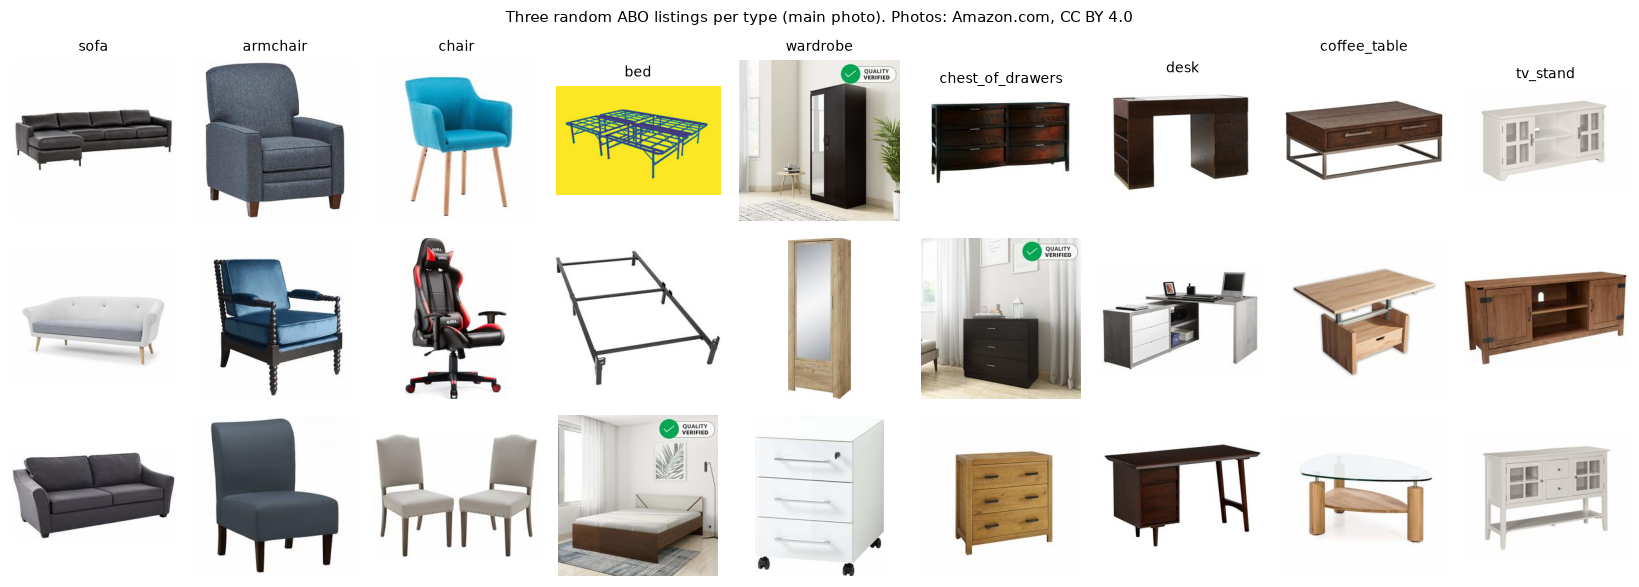

In [18]:
fig, axes = plt.subplots(3, 9, figsize=(15, 5.4))
main = views[views["view"] == 0].assign(t=lambda x: abo.loc[x["row"], "furniture_type"].values)
for i, t in enumerate(TYPES):
    for j, (_, r) in enumerate(main[main["t"] == t].sample(3, random_state=RANDOM_STATE).iterrows()):
        axes[j, i].imshow(Image.open(IMG_DIR / r["path"])); axes[j, i].axis("off")
    axes[0, i].set_title(t, fontsize=9)
plt.suptitle("Three random ABO listings per type (main photo). Photos: Amazon.com, CC BY 4.0", fontsize=10)
plt.tight_layout(); plt.show()

**Two lessons from section 1 applied here**
* **The same product appears many times.** Amazon lists one product on several country sites, and colour variants share photos. Listings are grouped when they share the item id, the model number, the main photo or a product-specific photo (`furniture/abo.py: abo_groups`); every split keeps a group on one side. Photos shared by more than 5 listings (logos, fabric swatches, room scenes) join nothing and are not used as inputs.
* **Small classes need their own numbers.** TV stands, chests of drawers and wardrobes, the classes where the mebel.kz model fails, are the smallest here too. With so few products, one fixed test split would hold only about four TV-stand products, so all ABO results are **grouped 5-fold cross-validation over every listing**, with per-class precision, recall and PR-AUC.

### 5.2 The models and the protocol

| Model | Inputs | Settings chosen by |
|---|---|---|
| specs (SVM) | height, longer and shorter side, footprint, volume, two ratios, log weight, weight per m³, 16 material flags, colour | inner grouped 3-fold CV inside each outer training fold: C ∈ {1, 3, 10, 30}, gamma ∈ {scale, 0.1} |
| photo: pretrained ResNet-18 + logistic regression | 512 numbers per photo from ResNet-18 trained on ImageNet (frozen), averaged over the listing's photos | inner CV: C ∈ {0.001, 0.003, 0.01, 0.1} |
| photo: small CNN | the photos themselves, 64 × 64 px, padded to a square on white | fixed in advance: 4 convolution blocks, 15 epochs, AdamW, one-cycle learning rate, flips and shifts; learning curve below |
| specs + photo | both input sets above, one logistic regression | inner CV: C ∈ {0.001, 0.003, 0.01, 0.1} |

* Every model sees the **same outer folds** and is scored on the **same 3,332 listings** that have a photo.
* Sizes are compared as *longer* and *shorter* side, because ABO's width/length order is not consistent.
* All classifiers use **balanced class weights**, so a TV stand counts as much as a sofa while learning, as it does in macro-F1.
* Nothing learned from the data sees the outer test fold: the scaler, the logistic regression and the CNN are fitted on the training fold only, and ResNet-18 is not trained at all.

In [19]:
from pathlib import Path
import io
OOF_FILE = Path("data/cache/abo_oof.npz")
if not OOF_FILE.exists():          # about 40 minutes on a laptop CPU; the saved run is used otherwise
    import tools.abo_experiment as experiment
    experiment.main()
z = np.load(OOF_FILE, allow_pickle=True)
ABO_NAMES, ABO_PROBS, abo_y, abo_folds = list(z["names"]), z["probs"], z["y"], z["folds"]
abo_scored = abo.set_index(["item_id", "domain"]).loc[list(zip(z["item_id"], z["domain"]))].reset_index()
assert (abo_scored["furniture_type"].map({t: i for i, t in enumerate(TYPES)}).values == abo_y).all()
print("listings scored:", len(abo_y), "| outer folds:", np.bincount(abo_folds).tolist())
print("settings chosen in the five folds:", z["chosen"].item())

listings scored: 3332 | outer folds: [667, 666, 667, 665, 667]
settings chosen in the five folds: {'specs (SVM)': [{'model__C': 3, 'model__gamma': 'scale'}, {'model__C': 3, 'model__gamma': 0.1}, {'model__C': 10, 'model__gamma': 'scale'}, {'model__C': 30, 'model__gamma': 'scale'}, {'model__C': 10, 'model__gamma': 0.1}], 'photo (ResNet-18 + logistic regression)': [{'model__C': 0.003}, {'model__C': 0.003}, {'model__C': 0.1}, {'model__C': 0.003}, {'model__C': 0.01}], 'specs + photo (logistic regression)': [{'model__C': 0.01}, {'model__C': 0.003}, {'model__C': 0.1}, {'model__C': 0.01}, {'model__C': 0.01}]}


### 5.3 The small CNN learns, and when it stops improving

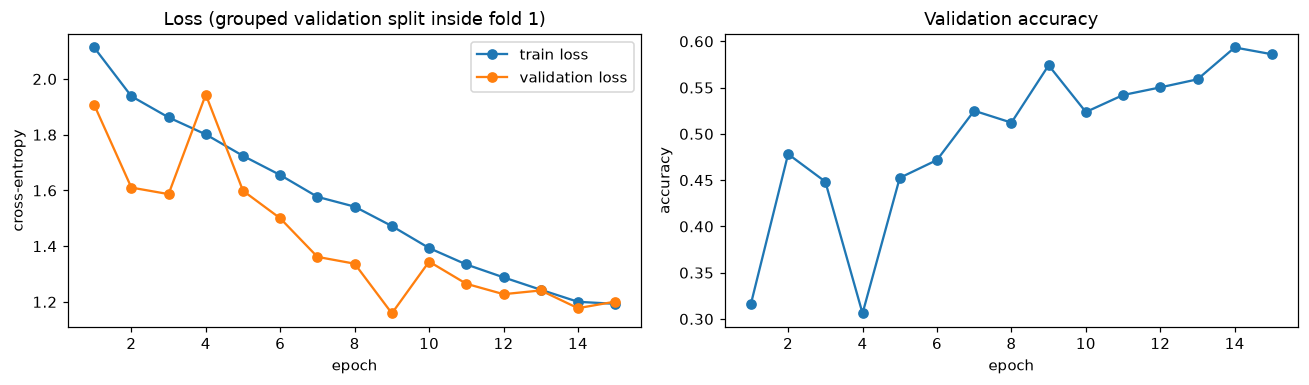

epoch,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
train loss,2.113,1.938,1.862,1.801,1.724,1.655,1.577,1.542,1.472,1.393,1.334,1.288,1.244,1.200,1.193
validation loss,1.908,1.610,1.587,1.944,1.599,1.500,1.362,1.337,1.159,1.345,1.265,1.228,1.241,1.177,1.201
validation accuracy,0.316,0.478,0.448,0.306,0.453,0.472,0.525,0.512,0.574,0.524,0.542,0.550,0.559,0.593,0.586


In [20]:
hist = pd.read_json(io.StringIO(z["history"].item()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
hist.plot(x="epoch", y=["train loss", "validation loss"], ax=axes[0], marker="o", title="Loss (grouped validation split inside fold 1)")
hist.plot(x="epoch", y="validation accuracy", ax=axes[1], marker="o", title="Validation accuracy", legend=False)
axes[0].set_ylabel("cross-entropy"); axes[1].set_ylabel("accuracy"); plt.tight_layout(); plt.show()
hist.round(3).set_index("epoch").T

**Reading the curve**
* Training loss falls steadily, from 2.11 to 1.19 in 15 epochs. Validation loss falls with it to 1.16 at epoch 9, then moves between 1.18 and 1.35 without a trend. Validation accuracy levels off at about 0.55-0.59 from epoch 12. The dip at epoch 4 comes when the one-cycle schedule reaches its highest learning rate.
* Training and validation loss stay close (1.19 vs 1.20): the network is **not overfitting, it is underfitting**. A model this small, on 64 × 64 photos and about 2,700 training listings, cannot learn more. More epochs would add a little; a larger network or larger photos would cost far more CPU time than we have.

### 5.4 Results: specs vs photo vs both

In [21]:
abo_w = 1 / pd.Series(abo_scored["group"]).map(abo_scored["group"].value_counts()).values
rows = []
for name, P in zip(ABO_NAMES, ABO_PROBS):
    pred = P.argmax(1)
    per_fold = [f1_score(abo_y[abo_folds == k], pred[abo_folds == k], average="macro") for k in range(5)]
    rows.append({"model": name, "CV macro-F1": f1_score(abo_y, pred, average="macro"),
                 "fold sd": np.std(per_fold), "per product (group)": f1_score(abo_y, pred, average="macro", sample_weight=abo_w),
                 "accuracy": accuracy_score(abo_y, pred)})
abo_summary = pd.DataFrame(rows).set_index("model")
abo_summary.round(3)

,CV macro-F1,fold sd,per product (group),accuracy
model,,,,
specs (SVM),0.662,0.019,0.679,0.788
photo (ResNet-18 + logistic regression),0.766,0.052,0.776,0.827
specs + photo (logistic regression),0.794,0.050,0.800,0.850
photo (small CNN),0.605,0.020,0.609,0.746


**What the comparison shows** (same 3,332 listings, same folds)
* **Photos beat specifications on Amazon: 0.766 vs 0.662 macro-F1.** The gap (0.10) is about twice the largest fold spread (± 0.052), so it is real.
* **Specs + photo is best (0.794), but only 0.028 above photo alone**, well inside the fold spread (± 0.05). We cannot claim the combination adds much beyond the photo.
* **The pretrained network wins clearly over the one we trained ourselves (0.766 vs 0.605).** ResNet-18 learned what furniture looks like from 1.2 million ImageNet photos; our small CNN sees about 2,700 products. With this little data, borrowing a trained network is the right choice, and the curve above shows why the small CNN stops at about 0.6.
* Counting each product once (per group) changes little (0.61-0.80, each within 0.02 of its per-listing score), because most Amazon groups are small.
* Specifications alone score 0.662 here vs 0.945 at mebel.kz. Amazon has no price, a third of the listings have no materials, and its categories mix more shapes. The same task is much harder in this store.
* *These are the Final's first photo models. Section 5.6 adds stronger pretrained encoders and a fine-tuned network on the same folds: the best, DINOv2, reaches 0.844 alone and 0.851 with the specifications.*

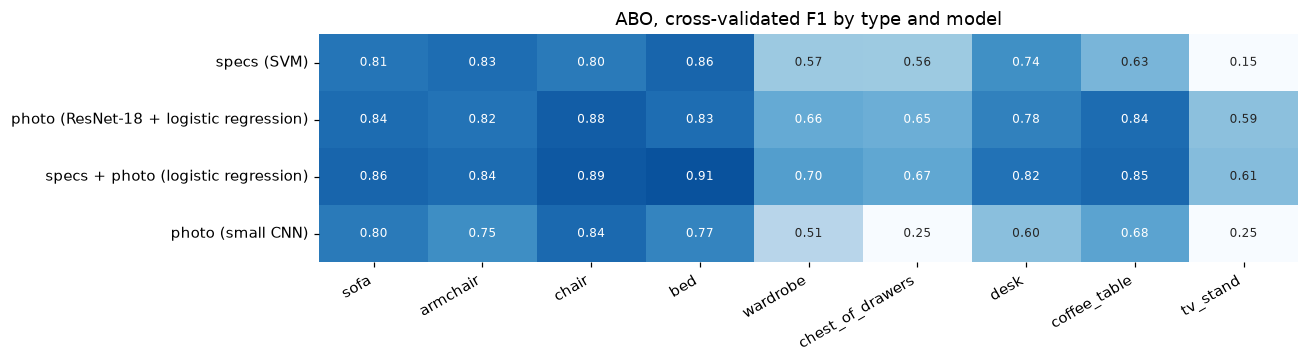

specs (SVM)               photo (ResNet-18 + logistic regression)               specs + photo (logistic regression)                \
                   precision recall PR-AUC                               precision recall PR-AUC                           precision recall PR-AUC   
chest_of_drawers       0.516  0.623  0.632                                   0.636  0.660  0.578                               0.633  0.717  0.596   
tv_stand               1.000  0.083  0.338                                   0.579  0.611  0.596                               0.575  0.639  0.642   
desk                   0.780  0.706  0.775                                   0.785  0.779  0.818                               0.828  0.816  0.840   
wardrobe               0.494  0.667  0.601                                   0.598  0.742  0.672                               0.662  0.742  0.718   
coffee_table           0.503  0.827  0.691                                   0.804  0.871  0.861                               0.799  0.906  0.858   

                 photo (small CNN)                
                         precision recall PR-AUC  
chest_of_drawers             0.185  0.377  0.198  
tv_stand                     0.179  0.389  0.215  
desk                         0.600  0.596  0.633  
wardrobe                     0.387  0.727  0.507  
coffee_table                 0.683  0.683  0.666

In [22]:
def class_table(P, y):
    pred = P.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(len(TYPES)), zero_division=0)
    ap = [average_precision_score(y == k, P[:, k]) for k in range(len(TYPES))]
    return pd.DataFrame({"precision": p, "recall": r, "F1": f, "PR-AUC": ap, "listings": s}, index=TYPES)

ABO_TABLES = {name: class_table(P, abo_y) for name, P in zip(ABO_NAMES, ABO_PROBS)}
f1_by_class = pd.DataFrame({name: t["F1"] for name, t in ABO_TABLES.items()}).T
plt.figure(figsize=(12, 3.4))
sns.heatmap(f1_by_class, annot=True, fmt=".2f", cmap="Blues", vmin=0.3, vmax=1, cbar=False, annot_kws={"fontsize": 8})
plt.title("ABO, cross-validated F1 by type and model"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
FOCUS = ["chest_of_drawers", "tv_stand", "desk", "wardrobe", "coffee_table"]
pd.concat({name: t.loc[FOCUS, ["precision", "recall", "PR-AUC"]] for name, t in ABO_TABLES.items()}, axis=1).round(3)

**The Endterm hypothesis, tested on the case furniture** ("photos show what the numbers cannot: drawers vs open shelves")
* **TV stands: yes.** Specifications almost never predict a TV stand: recall 0.083, PR-AUC 0.338. With the photo, recall is 0.611 and PR-AUC 0.596; with both, 0.639 and 0.642. This is the largest gain of any class, but it rests on only 21 products.
* **Chests of drawers: mixed.** Recall rises from 0.623 to 0.717 and precision from 0.516 to 0.633 with both inputs, but PR-AUC does not (0.632 specs, 0.578 photo, 0.596 both). The photo moves borderline chests to the right side of the decision, but does not rank all chests better. With 39 products we cannot call it an improvement.
* **Desks, wardrobes and coffee tables gain clearly from the photo:** PR-AUC desk 0.775 → 0.840 and wardrobe 0.601 → 0.718 (both inputs), coffee table 0.691 → 0.861 (photo alone).
* **The small CNN fails exactly on these classes** (PR-AUC about 0.2 for chests and TV stands): with a few dozen products per class, it cannot learn them from scratch.

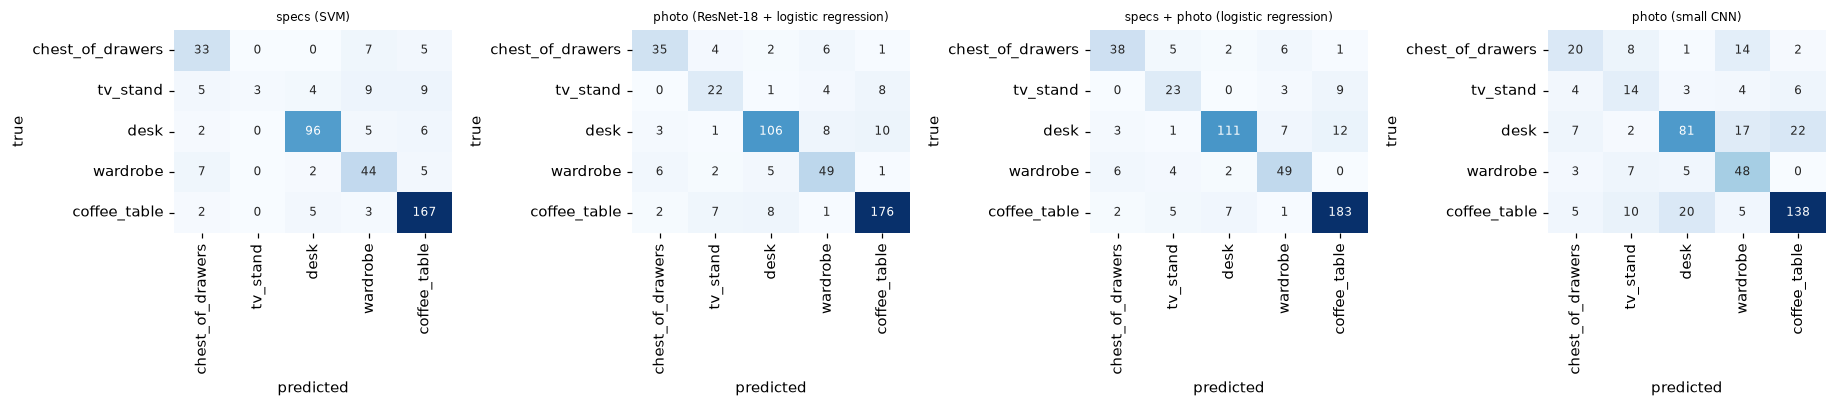

In [23]:
# the case-furniture border: chest of drawers, TV stand, desk, wardrobe, coffee table
idx = [TYPES.index(t) for t in FOCUS]
fig, axes = plt.subplots(1, len(ABO_NAMES), figsize=(4.2 * len(ABO_NAMES), 3.8))
for ax, name, P in zip(axes, ABO_NAMES, ABO_PROBS):
    m = np.isin(abo_y, idx)
    cm = pd.crosstab(pd.Categorical(np.array(TYPES)[abo_y[m]], FOCUS), pd.Categorical(np.array(TYPES)[P[m].argmax(1)], TYPES), dropna=False)
    sns.heatmap(cm[FOCUS], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 8})
    ax.set_title(name, fontsize=8); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

### 5.6 Stronger photo models (added after the survey)

> **In plain words.** People who tried the app said the models were the weak part. The photo comparison above uses one pretrained network (ResNet-18, 2015, trained on 1.3 million labelled photos) and one tiny network we trained ourselves. Here three stronger options run on **the same 3,332 listings and the same five outer folds**:
> * **CLIP** (OpenAI, 2021): learned to match 400 million internet photos with their captions, so it has seen a great deal of furniture with words like "TV stand" next to it. Frozen; 512 numbers per photo.
> * **DINOv2** (Meta, 2023): learned from 142 million photos with no labels at all, by comparing views of the same photo. Frozen; 384 numbers per photo.
> * **Fine-tuned ResNet-18:** the same ResNet-18, but its last two blocks and a new output layer are **trained on our photos** in each outer training fold (main photo + one more view, 160 px, 3 epochs, smaller learning rate for the pretrained blocks). This is the middle ground between "frozen" and "from scratch".
>
> Frozen features go into the same logistic regression as before, with C chosen by inner grouped CV. Code: `furniture/photos.py`, `tools/abo_encoders_experiment.py`.

In [24]:
OOF2_FILE = Path("data/cache/abo_oof_v2.npz")
if not OOF2_FILE.exists():         # about 1.5 hours on a laptop CPU (encoders + fine-tuning); the saved run is used otherwise
    import tools.abo_encoders_experiment as experiment2
    experiment2.main()
z2 = np.load(OOF2_FILE, allow_pickle=True)
assert (z2["folds"] == abo_folds).all() and (z2["y"] == abo_y).all(), "not the same listings and folds as 5.4"
ALL_NAMES = ABO_NAMES + list(z2["names"])
ALL_PROBS = np.concatenate([ABO_PROBS, z2["probs"]])
print("settings chosen in the five folds (C):", z2["chosen"].item())
rows = []
for name, P in zip(ALL_NAMES, ALL_PROBS):
    pred = P.argmax(1)
    per_fold = [f1_score(abo_y[abo_folds == k], pred[abo_folds == k], average="macro") for k in range(5)]
    rows.append({"model": name, "CV macro-F1": f1_score(abo_y, pred, average="macro"), "fold sd": np.std(per_fold),
                 "per product (group)": f1_score(abo_y, pred, average="macro", sample_weight=abo_w),
                 "accuracy": accuracy_score(abo_y, pred)})
abo_all = pd.DataFrame(rows).set_index("model").sort_values("CV macro-F1")
abo_all.round(3)

settings chosen in the five folds (C): {'photo (CLIP + logistic regression)': [0.003, 0.001, 0.001, 0.1, 0.001], 'photo (DINOv2 + logistic regression)': [0.01, 0.003, 0.1, 0.01, 0.01], 'specs + photo (CLIP, logistic regression)': [0.003, 0.001, 0.1, 0.1, 0.003], 'specs + photo (DINOv2, logistic regression)': [0.01, 0.003, 0.1, 0.1, 0.1]}


,CV macro-F1,fold sd,per product (group),accuracy
model,,,,
photo (small CNN),0.605,0.020,0.609,0.746
specs (SVM),0.662,0.019,0.679,0.788
photo (ResNet-18 + logistic regression),0.766,0.052,0.776,0.827
photo (fine-tuned ResNet-18),0.789,0.047,0.800,0.846
specs + photo (logistic regression),0.794,0.050,0.800,0.850
photo (CLIP + logistic regression),0.801,0.033,0.804,0.842
"specs + photo (CLIP, logistic regression)",0.812,0.050,0.819,0.848
photo (DINOv2 + logistic regression),0.844,0.057,0.846,0.869
"specs + photo (DINOv2, logistic regression)",0.851,0.053,0.852,0.874


In [25]:
# Paired view: the same five folds, macro-F1 of each photo model minus ResNet-18 + logistic regression (section 5.4)
REF = "photo (ResNet-18 + logistic regression)"
fold_f1 = {n: np.array([f1_score(abo_y[abo_folds == k], P.argmax(1)[abo_folds == k], average="macro") for k in range(5)])
           for n, P in zip(ALL_NAMES, ALL_PROBS)}
pd.DataFrame({n: {"mean change vs ResNet-18 frozen": (fold_f1[n] - fold_f1[REF]).mean(),
                  "sd of the change": (fold_f1[n] - fold_f1[REF]).std(),
                  "folds better": int(((fold_f1[n] - fold_f1[REF]) > 0).sum())}
              for n in ALL_NAMES if n != REF}).T.round(3)

,mean change vs ResNet-18 frozen,sd of the change,folds better
specs (SVM),-0.099,0.041,0.0
specs + photo (logistic regression),0.029,0.014,5.0
photo (small CNN),-0.158,0.039,0.0
photo (CLIP + logistic regression),0.038,0.024,4.0
photo (DINOv2 + logistic regression),0.079,0.024,5.0
"specs + photo (CLIP, logistic regression)",0.049,0.015,5.0
"specs + photo (DINOv2, logistic regression)",0.087,0.020,5.0
photo (fine-tuned ResNet-18),0.026,0.028,4.0


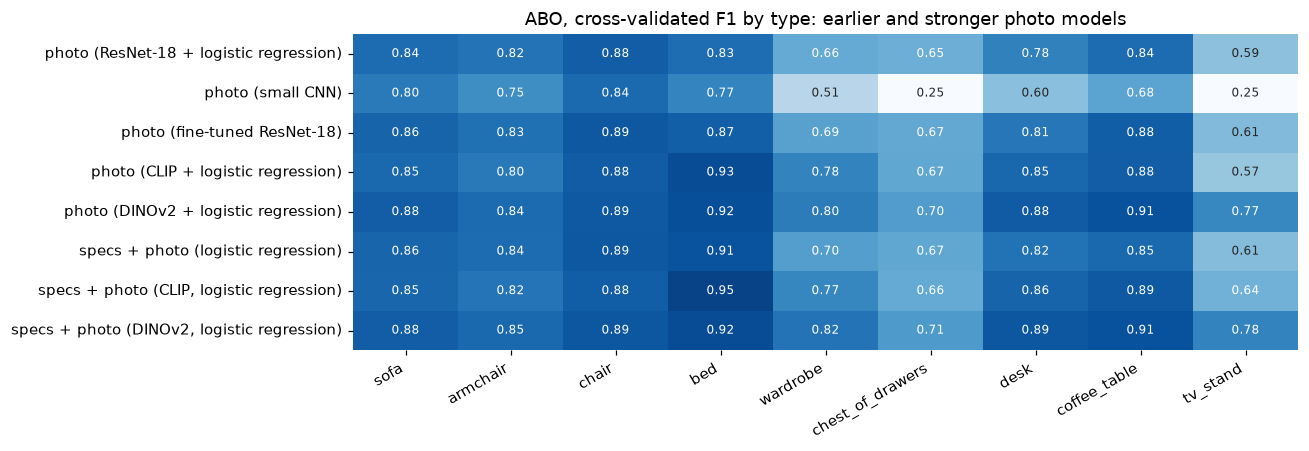

photo (ResNet-18 + LR)        photo (small CNN)        photo (fine-tuned ResNet-18)        photo (CLIP + LR)        photo (DINOv2 + LR)  \
                                 recall PR-AUC            recall PR-AUC                       recall PR-AUC            recall PR-AUC              recall   
chest_of_drawers                   0.66   0.58              0.38   0.20                         0.79   0.55              0.77   0.62                0.81   
tv_stand                           0.61   0.60              0.39   0.22                         0.53   0.62              0.64   0.66                0.78   
desk                               0.78   0.82              0.60   0.63                         0.79   0.84              0.84   0.91                0.90   
wardrobe                           0.74   0.67              0.73   0.51                         0.76   0.77              0.79   0.84                0.80   
coffee_table                       0.87   0.86              0.68   0.67                         0.88   0.93              0.89   0.92                0.93   

                        specs + photo (LR)        specs + photo (CLIP, LR)        specs + photo (DINOv2, LR)         
                 PR-AUC             recall PR-AUC                   recall PR-AUC                     recall PR-AUC  
chest_of_drawers   0.61               0.72   0.60                     0.75   0.57                       0.79   0.63  
tv_stand           0.78               0.64   0.64                     0.67   0.61                       0.78   0.79  
desk               0.94               0.82   0.84                     0.87   0.89                       0.90   0.95  
wardrobe           0.80               0.74   0.72                     0.76   0.80                       0.85   0.84  
coffee_table       0.97               0.91   0.86                     0.90   0.92                       0.93   0.97

In [26]:
ALL_TABLES = {name: class_table(P, abo_y) for name, P in zip(ALL_NAMES, ALL_PROBS)}
SHOW = [REF, "photo (small CNN)", "photo (fine-tuned ResNet-18)", "photo (CLIP + logistic regression)",
        "photo (DINOv2 + logistic regression)", "specs + photo (logistic regression)",
        "specs + photo (CLIP, logistic regression)", "specs + photo (DINOv2, logistic regression)"]
plt.figure(figsize=(12, 4.2))
sns.heatmap(pd.DataFrame({n: ALL_TABLES[n]["F1"] for n in SHOW}).T, annot=True, fmt=".2f", cmap="Blues", vmin=0.3, vmax=1,
            cbar=False, annot_kws={"fontsize": 8})
plt.title("ABO, cross-validated F1 by type: earlier and stronger photo models"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()
pd.concat({n.replace("logistic regression", "LR"): ALL_TABLES[n].loc[FOCUS, ["recall", "PR-AUC"]] for n in SHOW}, axis=1).round(2)

**What the stronger encoders change** (same 3,332 listings, same five folds as 5.4)
* **DINOv2 is the best photo model: 0.844 macro-F1, against 0.766 for frozen ResNet-18** (+0.079, better in all 5 folds, sd of the change 0.024). With the specifications added it reaches **0.851**, the best result on ABO (0.794 before). CLIP is in between (0.801, better than ResNet-18 in 4 of 5 folds).
* **The ranking follows how much each encoder has seen:** ResNet-18 (1.3 M labelled photos) < CLIP (400 M captioned photos) < DINOv2 (142 M curated photos, trained to describe *what an object looks like*, not what a caption says). DINOv2 vectors are smaller (384 vs 512 numbers) and still better: they separate shapes, which is what furniture types differ in.
* **Fine-tuning ResNet-18 helps a little: 0.789 vs 0.766** (better in 4 of 5 folds, but the change, +0.026 ± 0.028, is about one sd). It needed about 50 minutes of CPU for five folds and still loses to a frozen DINOv2 with a logistic regression that trains in seconds. With about 2,700 training products, a better pretrained encoder beats training more of a weaker one.
* **The model we trained ourselves stays far behind** (small CNN 0.605): the gap between "learned from scratch" and "borrowed" is now 0.24 macro-F1.
* **The case furniture, the Endterm hypothesis:** with DINOv2 (+ specs), TV-stand recall rises to **0.78** (0.08 with specs only, 0.64 with ResNet-18 + specs) and PR-AUC to 0.79; desk PR-AUC 0.95, wardrobe 0.84, coffee table 0.97. **Chests of drawers are still the weak class** (PR-AUC 0.57-0.63 for every model): the photos and the sizes of a chest and a low cabinet look alike, and with 39 products the numbers are uncertain.
* The fold spread is ± 0.05 for every photo model, so differences below about 0.03 (for example CLIP alone vs CLIP + specs) are not reliable; the paired table counts how many of the same five folds each model wins.

### 5.7 An outside test: IKEA catalogue photos

> **In plain words.** Every ABO score above comes from Amazon photos only. Here each photo model is trained on **all ABO listings** and then shown **IKEA catalogue photos it has never seen**, from another company and another photo style (Tautkute et al. 2017; rights and selection in section 3.2 and `DATA_CARD.md`). Only 221 IKEA photos can be labelled with our types, mostly beds, chairs and sofas, so this is a **check of transfer**, not a full benchmark. For the fine-tuned network, the five fold models are averaged (no network sees IKEA during training).

In [27]:
ik = pd.read_csv("data/processed/ikea_images.csv"); ik = ik[ik["ok"]].reset_index(drop=True)
y_ik = z2["ikea_y"]; present = sorted(set(y_ik))
print("IKEA photos:", len(ik), "|", ik["furniture_type"].value_counts().to_dict())
ik_rows = {}
for name, P in zip(z2["ikea_names"], z2["ikea_probs"]):
    pred = P.argmax(1)
    ik_rows[name] = {"accuracy": accuracy_score(y_ik, pred),
                     "macro-F1 (types present)": f1_score(y_ik, pred, labels=present, average="macro"),
                     **{f"recall {TYPES[k]}": (pred[y_ik == k] == k).mean() for k in present}}
ikea_table = pd.DataFrame(ik_rows).T
ikea_table.insert(0, "ABO CV macro-F1", [abo_all.at[n, "CV macro-F1"] for n in ikea_table.index])
ikea_table.round(3)

IKEA photos: 221 | {'chair': 106, 'bed': 54, 'sofa': 40, 'desk': 8, 'wardrobe': 7, 'chest_of_drawers': 4, 'tv_stand': 2}


,ABO CV macro-F1,accuracy,macro-F1 (types present),recall sofa,recall chair,recall bed,recall wardrobe,recall chest_of_drawers,recall desk,recall tv_stand
photo (ResNet-18 + logistic regression),0.766,0.810,0.755,0.950,0.792,0.722,1.000,0.75,0.875,0.5
photo (CLIP + logistic regression),0.801,0.846,0.648,0.925,0.858,0.833,0.429,1.00,0.875,0.0
photo (DINOv2 + logistic regression),0.844,0.846,0.880,0.975,0.792,0.815,1.000,1.00,0.875,1.0
photo (fine-tuned ResNet-18),0.789,0.774,0.767,0.950,0.840,0.463,1.000,1.00,0.875,0.5


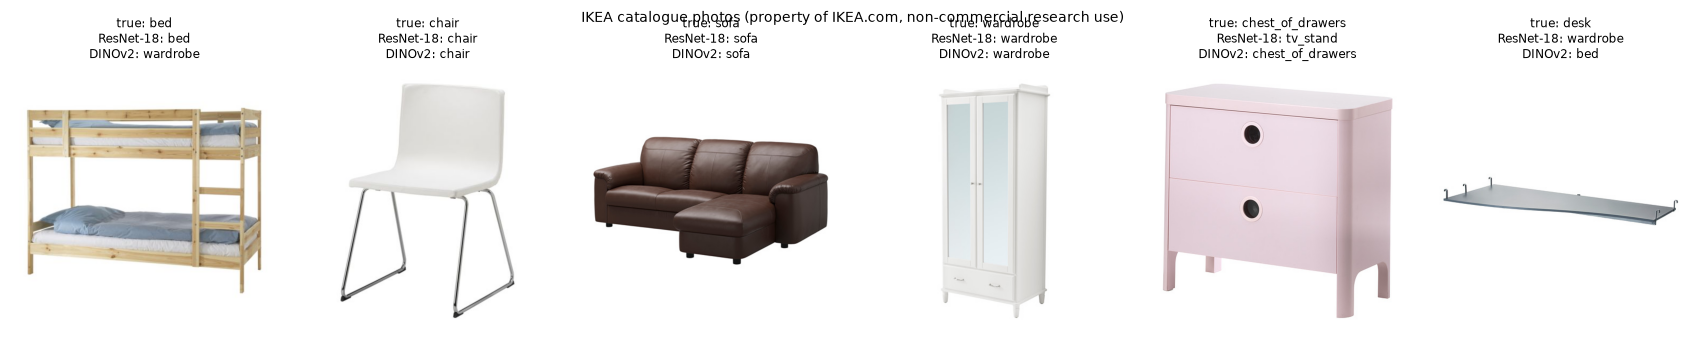

In [28]:
# Six IKEA photos with the prediction of the best and of the oldest frozen encoder
from furniture.photos import load_images
best_ik = ikea_table["macro-F1 (types present)"].idxmax()
P_best = z2["ikea_probs"][list(z2["ikea_names"]).index(best_ik)]
P_ref = z2["ikea_probs"][list(z2["ikea_names"]).index(REF)]
pick = ik.groupby("furniture_type").head(1).index[:6]
fig, axes = plt.subplots(1, len(pick), figsize=(2.6 * len(pick), 3.2))
for ax, i in zip(axes, pick):
    ax.imshow(Image.open(Path("data/external/ikea_images") / ik.at[i, "path"])); ax.axis("off")
    ax.set_title(f"true: {ik.at[i, 'furniture_type']}\nResNet-18: {TYPES[P_ref[i].argmax()]}\n{best_ik.split('(')[1].split(' ')[0]}: {TYPES[P_best[i].argmax()]}", fontsize=8)
plt.suptitle("IKEA catalogue photos (property of IKEA.com, non-commercial research use)", fontsize=9)
plt.tight_layout(); plt.show()

**What the outside test shows** (221 IKEA photos: chair 106, bed 54, sofa 40, desk 8, wardrobe 7, chest of drawers 4, TV stand 2)
* **DINOv2 transfers best: macro-F1 0.880** over the seven types present (accuracy 0.846), against 0.755 for ResNet-18 and 0.767 for the fine-tuned network. It is the only model that finds both IKEA TV stands, all four chests and all seven wardrobes.
* **CLIP transfers worst on the rare classes (0.648):** it misses the TV stands and 4 of 7 wardrobes, although its accuracy (0.846) equals DINOv2's on the common classes. A caption-trained encoder seems to tie these products to Amazon's photo style more than to their shape.
* **The fine-tuned ResNet-18 loses beds** (recall 0.46 vs 0.72 frozen): training its last blocks on Amazon's photos made it more Amazon-specific. That is the risk of fine-tuning on a small, one-source set.
* **Limits:** the rare classes have 2-8 photos each, so one photo moves their recall a lot; the common ones (chair, bed, sofa) carry the accuracy. This is a check that the ABO ranking is not an Amazon accident (it holds: DINOv2 first), not a precise score.

## 6. Does the mebel.kz model work in another store?

> **In plain words.** All our scores so far come from one Almaty store. Here a model is trained on **all mebel.kz listings** and asked to classify the **Amazon listings**. It may only use what both stores have: the sizes (as height, longer and shorter side) and, in a second version, the 16 material flags. No price (Amazon has none), no weight (mebel.kz has none), no colour (the stores name colours differently). Same SVM as the chosen model (C = 3). For comparison, the same model is also scored inside each store with grouped 5-fold CV.

In [29]:
from furniture.abo import size_features, spec_prep as abo_prep
from sklearn.pipeline import Pipeline as SkPipeline
mebel_x = size_features(df)   # rebuilds the 16 material flags from the materials text, as for ABO
abo_x = abo[abo[["height_cm", "long_cm", "short_cm"]].notna().all(axis=1)].reset_index(drop=True)
mf = lambda a, b: f1_score(a, b, average="macro", labels=TYPES)
INPUTS = {"sizes + materials": (SIZE + ABO_MATERIALS, ABO_MATERIALS), "sizes only": (SIZE, [])}
xmodel = lambda mats: SkPipeline([("prep", abo_prep(SIZE, materials=mats, colour=False)), ("model", SVC(C=3, gamma="scale"))])

XPRED, xrows = {}, []
for label, (feats, mats) in INPUTS.items():
    within_mebel = cross_val_predict(xmodel(mats), mebel_x[feats], mebel_x["furniture_type"], groups=df["group"], cv=cv)
    within_abo = cross_val_predict(xmodel(mats), abo_x[feats], abo_x["furniture_type"], groups=abo_x["group"], cv=cv)
    transfer = xmodel(mats).fit(mebel_x[feats], mebel_x["furniture_type"]).predict(abo_x[feats])
    XPRED[label] = {"within_abo": within_abo, "transfer": transfer}
    xrows.append({"inputs": label, "mebel.kz -> mebel.kz (grouped CV)": mf(mebel_x["furniture_type"], within_mebel),
                  "ABO -> ABO (grouped CV)": mf(abo_x["furniture_type"], within_abo),
                  "mebel.kz -> ABO": mf(abo_x["furniture_type"], transfer)})
print(f"listings: mebel.kz {len(mebel_x)}, ABO with all three sizes {len(abo_x)}")
pd.DataFrame(xrows).set_index("inputs").round(3)

listings: mebel.kz 3961, ABO with all three sizes 2886


,mebel.kz -> mebel.kz (grouped CV),ABO -> ABO (grouped CV),mebel.kz -> ABO
inputs,,,
sizes + materials,0.945,0.730,0.528
sizes only,0.890,0.746,0.606


**The 0.95 does not travel.**
* With sizes only, the mebel.kz model scores **0.890 at home** (grouped CV), **0.746 for a model trained on Amazon itself**, and **0.606 when the mebel.kz model is used on Amazon**.
* Adding materials helps at home (0.890 → 0.945) but **hurts in the other store** (0.606 → 0.528). The table below shows why: mebel.kz lists chipboard on 78% of its listings, Amazon on 3%, and 32% of Amazon listings name no material at all. The mebel.kz model learned "no chipboard = upholstered furniture", so Amazon desks without a material text look like sofas to it. Materials are partly a description of *the store's form*, not of the furniture.

In [30]:
# The two stores describe materials differently: share of listings with each material flag
mat_share = pd.DataFrame({"mebel.kz": mebel_x[ABO_MATERIALS].mean(), "Amazon (ABO)": abo_x[ABO_MATERIALS].mean()})
mat_share.loc["(no material at all)"] = [(mebel_x[ABO_MATERIALS].sum(axis=1) == 0).mean(), (abo_x[ABO_MATERIALS].sum(axis=1) == 0).mean()]
mat_share.round(2).T

,mat_chipboard,mat_mdf,mat_fibreboard,mat_solid_wood,mat_plywood,mat_veneer,mat_metal,mat_plastic,mat_glass,mat_mirror,mat_fabric,mat_leather,mat_foam,mat_spring,mat_rattan,mat_stone,(no material at all)
mebel.kz,0.78,0.37,0.22,0.52,0.32,0.03,0.44,0.23,0.01,0.0,0.19,0.02,0.00,0.04,0.02,0.0,0.00
Amazon (ABO),0.03,0.00,0.00,0.23,0.01,0.00,0.10,0.02,0.00,0.0,0.26,0.09,0.01,0.00,0.00,0.1,0.32


,F1 inside ABO,F1 mebel.kz -> ABO,recall mebel.kz -> ABO,"F1 mebel.kz -> ABO, with materials",ABO listings
sofa,0.877,0.816,0.757,0.397,869
armchair,0.893,0.833,0.828,0.800,785
chair,0.891,0.702,0.571,0.818,541
bed,0.899,0.794,0.861,0.423,237
wardrobe,0.690,0.503,0.578,0.507,64
chest_of_drawers,0.615,0.297,0.809,0.463,47
desk,0.679,0.463,0.438,0.291,128
coffee_table,0.739,0.624,0.824,0.540,188
tv_stand,0.431,0.419,0.481,0.516,27


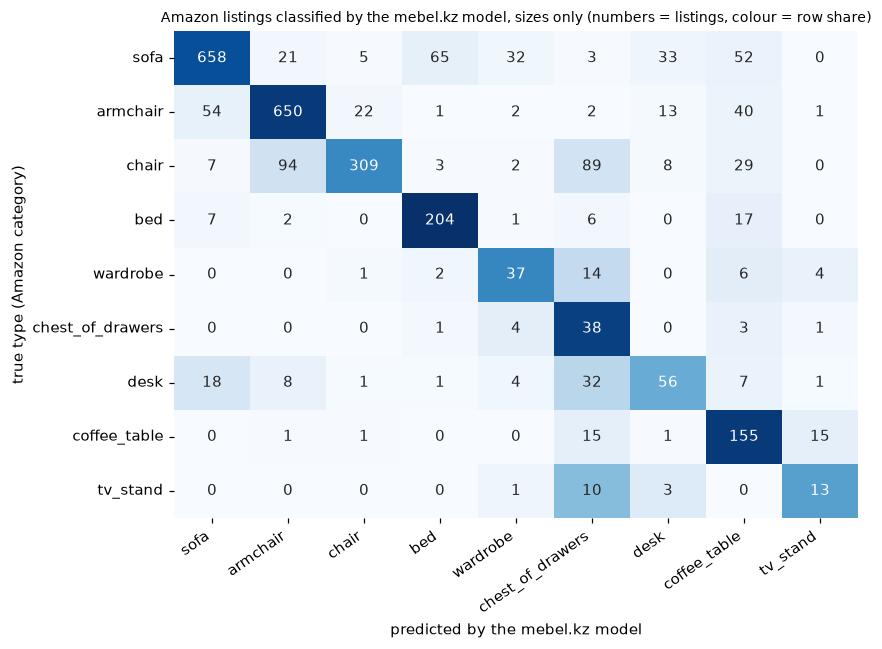

In [31]:
best_x = "sizes only"
transfer = XPRED[best_x]["transfer"]
xt = pd.DataFrame({"F1 inside ABO": f1_score(abo_x["furniture_type"], XPRED[best_x]["within_abo"], labels=TYPES, average=None),
                   "F1 mebel.kz -> ABO": f1_score(abo_x["furniture_type"], transfer, labels=TYPES, average=None),
                   "recall mebel.kz -> ABO": precision_recall_fscore_support(abo_x["furniture_type"], transfer, labels=TYPES, zero_division=0)[1],
                   "F1 mebel.kz -> ABO, with materials": f1_score(abo_x["furniture_type"], XPRED["sizes + materials"]["transfer"], labels=TYPES, average=None),
                   "ABO listings": abo_x["furniture_type"].value_counts().reindex(TYPES).values}, index=TYPES)
display(xt.round(3))
cmx = pd.crosstab(abo_x["furniture_type"], pd.Series(transfer, name="predicted by the mebel.kz model")).reindex(index=TYPES, columns=TYPES, fill_value=0)
plt.figure(figsize=(8, 6))
sns.heatmap(cmx.div(cmx.sum(axis=1), axis=0), annot=cmx, fmt="d", cmap="Blues", cbar=False)
plt.title("Amazon listings classified by the mebel.kz model, sizes only (numbers = listings, colour = row share)", fontsize=9)
plt.ylabel("true type (Amazon category)"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

**Which types transfer** (mebel.kz model, sizes only, on Amazon)
* **Seating and beds transfer well:** sofa F1 0.816, armchair 0.833, bed 0.794. Their shapes are the same in both stores.
* **Chairs drop to 0.702:** Amazon chairs are taller (median 90 cm vs 79 cm), so many are taken for armchairs.
* **Case furniture does not transfer:** chest of drawers 0.297 (most real chests are found, recall 0.809, but many other Amazon listings are also called chests), TV stand 0.419, desk 0.463, wardrobe 0.503. Amazon's wardrobes are lower (median 165 cm vs 212 cm) and its coffee tables longer (110 cm vs 58 cm). The size thresholds the model learned are mebel.kz's own catalogue, not a law of furniture.

In [32]:
# Typical sizes of each type in the two stores (medians, cm)
pd.concat({"mebel.kz": mebel_x.groupby("furniture_type")[["height_cm", "long_cm", "short_cm"]].median(),
           "Amazon (ABO)": abo_x.groupby("furniture_type")[["height_cm", "long_cm", "short_cm"]].median()}, axis=1).reindex(TYPES).round(0)

mebel.kz                  Amazon (ABO)                 
                 height_cm long_cm short_cm    height_cm long_cm short_cm
furniture_type                                                           
sofa                  86.0   220.0    105.0         86.0   198.0     91.0
armchair              81.0    86.0     79.0         89.0    91.0     82.0
chair                 79.0    57.0     53.0         90.0    61.0     54.0
bed                   95.0   212.0    171.0        117.0   210.0    163.0
wardrobe             212.0   110.0     50.0        165.0    94.0     42.0
chest_of_drawers      87.0   105.0     44.0         89.0   100.0     45.0
desk                  76.0   120.0     60.0         76.0   122.0     60.0
coffee_table          43.0    58.0     45.0         45.0   110.0     60.0
tv_stand              54.0   160.0     40.0         64.0   135.0     40.0

## 7. Price on the same listings: specifications, then specifications + product name

> **In plain words.** Sections 1-6 show that the type is mostly a question of size. The price is not: two sofas of the same size can differ by a factor of three because of the fabric, the mechanism or the brand line. Here the same 3,961 mebel.kz listings, the **same 793 test listings** and the **same groups** (section 1.3) are used to predict the **price**.
>
> * **Target:** log of the price in tenge (prices range from 9,000 to 3.4 million ₸; the log turns "30% too high" into the same error for a chair and a sofa). Errors are reported back in tenge.
> * **Inputs, specifications:** the three sizes, footprint, volume, the two ratios, the 16 material flags, the colour and the type. **Never** the price itself, the series, the article number or the URL.
> * **Second source, text on the same listings:** the **product name**, e.g. *"Диван прямой Линс Велюр Голубой"* (straight sofa, model Линс, velour, light blue). Names are short factual labels, like the specifications. We do **not** use the long page descriptions or the photos: the store's copyright notice covers page text and photos (section 3).
> * **Two ways to read the name:** our own simple model (**TF-IDF** word and character pieces) and a **pretrained** multilingual sentence encoder (**multilingual-e5-small**, Wang et al. 2024, not fine-tuned), each followed by a regressor.
> * **The leakage check.** The name contains the design's own name (*Линс*). The groups already keep every listing of a design on one side, but to be sure the text is not just memorising "Линс costs X", every text model is also run with that word **masked** (`furniture/price.py: mask_name`).
> * **Protocol:** grouped 5-fold CV on the 2,971 training listings (the folds of section 1, stratified by type), settings tuned on those folds by mean absolute error, the model chosen by CV, the test set used once.

In [33]:
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from lightgbm import LGBMRegressor
from furniture.price import SIZE_NUM, CATEGORICAL, E5_MODEL, text_column, spec_prep, tfidf, e5_embed, price_metrics

pdf = df.copy()
pdf["text"], pdf["text_masked"] = text_column(pdf, masked=False), text_column(pdf, masked=True)
E5_COLS = {}
for col in ["text", "text_masked"]:   # about 2 minutes on CPU the first time, then read from data/cache
    e = e5_embed(pdf[col].tolist(), cache_name=f"name_e5_{col}")
    E5_COLS[col] = [f"{col}_e{i}" for i in range(e.shape[1])]
    pdf = pd.concat([pdf, pd.DataFrame(e, columns=E5_COLS[col], index=pdf.index)], axis=1)
ptrain, ptest = pdf.loc[train.index], pdf.loc[test.index]
py_train, py_test = np.log(ptrain["price_kzt"].values), np.log(ptest["price_kzt"].values)
PSPLITS = list(cv.split(ptrain, ptrain["furniture_type"], ptrain["group"]))
SPECS = SIZE_NUM + MATERIALS + CATEGORICAL
print(f"training {len(ptrain)} listings in {ptrain['group'].nunique()} groups | test {len(ptest)} listings in {ptest['group'].nunique()} designs")
print("price, training: median", f"{ptrain['price_kzt'].median():,.0f}", "KZT, range", f"{ptrain['price_kzt'].min():,.0f} - {ptrain['price_kzt'].max():,.0f}")
print("encoder:", E5_MODEL, "| embedding size", len(E5_COLS["text"]))
pd.DataFrame({"name": ptrain["name"].head(6).values, "masked name (leakage check)": ptrain["text_masked"].head(6).values})

C:\Users\ASUS\Desktop\ml final project\furniture-prediction-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


training 2971 listings in 315 groups | test 793 listings in 92 designs
price, training: median 229,610 KZT, range 30,550 - 2,067,050
encoder: intfloat/multilingual-e5-small | embedding size 384


,name,masked name (leakage check)
0,Детская кровать Бони 80 Шенилл Светло-розовый,Детская кровать модель 80 Шенилл Светло-розовый
1,Детская кровать Дебби-1 80 Мех Молочный,Детская кровать модель 80 Мех Молочный
2,Детская кровать Дебби-1 80 Мех Серый,Детская кровать модель 80 Мех Серый
3,Детская кровать Дебби-1 80 Вельвет Голубой,Детская кровать модель 80 Вельвет Голубой
4,Детская кровать Дебби-1 80 Вельвет Мятный,Детская кровать модель 80 Вельвет Мятный
5,Детская кровать Дебби-1 80 Вельвет Оливковый,Детская кровать модель 80 Вельвет Оливковый


In [34]:
def price_pipe(model, text=None, emb=None, specs=True):
    parts = [("specs", spec_prep(MATERIALS), SPECS)] if specs else []
    if text:
        parts.append(("text", tfidf(), text))
    if emb:
        parts.append(("emb", "passthrough", E5_COLS[emb]))   # e5 vectors are already normalised
    return SkPipeline([("prep", ColumnTransformer(parts)), ("model", model)])

RIDGE = {"model__alpha": [0.3, 1, 3, 10, 30]}
RIDGE_E5 = {"model__alpha": [0.03, 0.1, 0.3, 1, 3]}
SVR_GRID = {"model__C": [0.3, 1, 3], "model__epsilon": [0.05, 0.1]}
# name -> (inputs, pipeline, search space)
PRICE_MODELS = {
    "ridge | specs": ("specs", price_pipe(Ridge()), RIDGE),
    "random forest | specs": ("specs", price_pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                              {"model__min_samples_leaf": [1, 3, 10], "model__max_features": [0.3, 0.6]}),
    "boosting | specs": ("specs", price_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                         {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31], "model__min_samples_leaf": [10, 30]}),
    "SVR | specs": ("specs", price_pipe(SVR()), SVR_GRID),
    # added after the survey: LightGBM, a stronger gradient-boosting library (leaf-wise trees, column sampling)
    "LightGBM | specs": ("specs", price_pipe(LGBMRegressor(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
                         {"model__learning_rate": [0.03, 0.06], "model__num_leaves": [15, 31], "model__min_child_samples": [10, 30],
                          "model__colsample_bytree": [0.3, 0.7]}),
    "ridge | name only (TF-IDF)": ("name only", price_pipe(Ridge(), text="text", specs=False), RIDGE),
    "ridge | specs + name (TF-IDF)": ("specs + name, own", price_pipe(Ridge(), text="text"), RIDGE),
    "SVR | specs + name (TF-IDF)": ("specs + name, own", price_pipe(SVR(), text="text"), SVR_GRID),
    "ridge | specs + name (e5)": ("specs + name, pretrained", price_pipe(Ridge(), emb="text"), RIDGE_E5),
    "SVR | specs + name (e5)": ("specs + name, pretrained", price_pipe(SVR(), emb="text"), SVR_GRID),
    "ridge | specs + masked name (TF-IDF)": ("masked name", price_pipe(Ridge(), text="text_masked"), RIDGE),
    "SVR | specs + masked name (TF-IDF)": ("masked name", price_pipe(SVR(), text="text_masked"), SVR_GRID),
    "SVR | specs + masked name (e5)": ("masked name", price_pipe(SVR(), emb="text_masked"), SVR_GRID),
}

fold_mae = lambda oof: np.array([np.mean(np.abs(np.exp(oof[va]) - np.exp(py_train[va]))) for _, va in PSPLITS])
PRICE_OOF, PRICE_TEST, PRICE_FIT, PRICE_FOLDS, prow = {}, {}, {}, {}, []

def add_row(name, inputs, oof, pred, params=""):
    PRICE_OOF[name], PRICE_TEST[name], PRICE_FOLDS[name] = oof, pred, fold_mae(oof)
    c, t = price_metrics(py_train, oof), price_metrics(py_test, pred)
    prow.append({"model": name, "inputs": inputs, "CV MAE (KZT)": c["MAE (KZT)"], "CV fold sd": PRICE_FOLDS[name].std(),
                 "CV MAPE": c["MAPE"], "CV R² (log)": c["R² (log)"], "test MAE (KZT)": t["MAE (KZT)"], "test MAPE": t["MAPE"],
                 "test R² (log)": t["R² (log)"], "test MAE per design": price_metrics(py_test, pred, weight=w.values)["MAE (KZT)"],
                 "settings": params})

# baselines: the median price of all training listings, and of the listing's type (computed inside each fold)
oof_all, oof_type = np.zeros(len(ptrain)), np.zeros(len(ptrain))
for tr, va in PSPLITS:
    oof_all[va] = np.median(py_train[tr])
    oof_type[va] = ptrain.iloc[va]["furniture_type"].map(pd.Series(py_train[tr]).groupby(ptrain.iloc[tr]["furniture_type"].values).median()).values
add_row("median price", "none", oof_all, np.full(len(ptest), np.median(py_train)))
add_row("median price of the type", "type", oof_type, ptest["furniture_type"].map(pd.Series(py_train).groupby(ptrain["furniture_type"].values).median()).values)

for name, (inputs, p, grid) in PRICE_MODELS.items():
    s = GridSearchCV(p, grid, cv=PSPLITS, scoring="neg_mean_absolute_error", n_jobs=1 if "forest" in name else -1).fit(ptrain, py_train)
    PRICE_FIT[name] = s.best_estimator_
    oof = cross_val_predict(clone(s.best_estimator_), ptrain, py_train, cv=PSPLITS)
    add_row(name, inputs, oof, s.best_estimator_.predict(ptest), {k.replace("model__", ""): v for k, v in s.best_params_.items()})

price_table = pd.DataFrame(prow).set_index("model")
fmt = {c: "{:,.0f}" for c in ["CV MAE (KZT)", "CV fold sd", "test MAE (KZT)", "test MAE per design"]}
fmt.update({c: "{:.3f}" for c in ["CV MAPE", "CV R² (log)", "test MAPE", "test R² (log)"]})
price_table.style.format(fmt)

,inputs,CV MAE (KZT),CV fold sd,CV MAPE,CV R² (log),test MAE (KZT),test MAPE,test R² (log),test MAE per design,settings
model,,,,,,,,,,
median price,none,"136,107","14,196",0.637,-0.022,"148,863",0.693,-0.008,"183,256",
median price of the type,type,"94,806","8,848",0.416,0.476,"97,901",0.416,0.596,"107,457",
ridge | specs,specs,"64,686","4,832",0.263,0.761,"54,265",0.237,0.821,"76,064",{'alpha': 10}
random forest | specs,specs,"61,436","6,336",0.250,0.766,"54,292",0.221,0.826,"76,550","{'max_features': 0.3, 'min_samples_leaf': 3}"
boosting | specs,specs,"61,641","5,386",0.252,0.767,"55,029",0.226,0.835,"75,830","{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 10}"
SVR | specs,specs,"61,719","4,140",0.245,0.774,"54,162",0.207,0.850,"78,302","{'C': 1, 'epsilon': 0.05}"
LightGBM | specs,specs,"60,591","5,675",0.249,0.769,"53,666",0.221,0.840,"73,030","{'colsample_bytree': 0.3, 'learning_rate': 0.03, 'min_child_samples': 30, 'num_leaves': 15}"
ridge | name only (TF-IDF),name only,"84,858","10,525",0.352,0.578,"86,937",0.358,0.662,"103,950",{'alpha': 1}
ridge | specs + name (TF-IDF),"specs + name, own","60,849","5,698",0.247,0.781,"51,404",0.218,0.841,"70,877",{'alpha': 10}


In [35]:
SPEC_NAMES = [n for n, (inp, _, _) in PRICE_MODELS.items() if inp == "specs"]
UNMASKED = [n for n, (inp, _, _) in PRICE_MODELS.items() if inp != "masked name"]
PRICE_SPECS_BEST = min(SPEC_NAMES, key=lambda n: price_table.at[n, "CV MAE (KZT)"])
PRICE_BEST = min(UNMASKED, key=lambda n: price_table.at[n, "CV MAE (KZT)"])
NAME_MODELS = [n for n, (inp, _, _) in PRICE_MODELS.items() if inp.startswith("specs + name")]
PRICE_NAME_BEST = min(NAME_MODELS, key=lambda n: price_table.at[n, "CV MAE (KZT)"])
print("best specifications-only model by CV:", PRICE_SPECS_BEST)
print("chosen model by CV (any inputs):    ", PRICE_BEST)

# Paired comparison: the same five folds, MAE of each model minus MAE of the best specifications-only model
base = PRICE_FOLDS[PRICE_SPECS_BEST]
paired = pd.DataFrame({n: {"inputs": price_table.at[n, "inputs"], "mean change in fold MAE (KZT)": (PRICE_FOLDS[n] - base).mean(),
                           "sd of the change": (PRICE_FOLDS[n] - base).std(), "folds better": int(((PRICE_FOLDS[n] - base) < 0).sum()),
                           "test MAE change (KZT)": price_table.at[n, "test MAE (KZT)"] - price_table.at[PRICE_SPECS_BEST, "test MAE (KZT)"]}
                       for n in PRICE_MODELS if n != PRICE_SPECS_BEST}).T
paired.style.format({"mean change in fold MAE (KZT)": "{:,.0f}", "sd of the change": "{:,.0f}", "test MAE change (KZT)": "{:,.0f}"})

best specifications-only model by CV: LightGBM | specs
chosen model by CV (any inputs):     SVR | specs + name (TF-IDF)


,inputs,mean change in fold MAE (KZT),sd of the change,folds better,test MAE change (KZT)
ridge | specs,specs,"4,114","4,215",2,599
random forest | specs,specs,835,"3,046",2,627
boosting | specs,specs,"1,051","1,440",1,"1,363"
SVR | specs,specs,"1,129","6,007",1,496
ridge | name only (TF-IDF),name only,"24,262","8,025",0,"33,271"
ridge | specs + name (TF-IDF),"specs + name, own",274,"3,704",3,"-2,262"
SVR | specs + name (TF-IDF),"specs + name, own","-1,500","3,784",3,"-1,920"
ridge | specs + name (e5),"specs + name, pretrained","4,123","5,075",1,"1,583"
SVR | specs + name (e5),"specs + name, pretrained",-337,"5,445",2,583
ridge | specs + masked name (TF-IDF),masked name,331,"4,001",2,"-2,169"


**What the table shows** (CV = grouped 5-fold CV on 2,971 training listings; test = the 793 saved listings, used once)
* **Baselines.** The median price of the type cuts the error of the overall median from 136,100 to 94,800 KZT (CV MAE). The type matters, but most of the price spread is *inside* a type.
* **Specifications** bring the CV MAE to 60,000-65,000 KZT (MAPE about 25%, R² on log price 0.76-0.77). The five model families are within 4,100 KZT of each other, less than their fold spread (± 4,000-6,000): LightGBM 60,591, forest 61,436, boosting 61,641, SVR 61,719, ridge 64,686. **LightGBM (added after the survey) is the best specifications-only model**, but only 845 KZT ahead of the forest, the Final's earlier best; on the same folds it beats the forest in 3 of 5.
* **The name alone** (ridge on TF-IDF) is much worse (84,900): the name does not replace the sizes.
* **Specifications + name with our own TF-IDF features and an SVR is the best model in CV: MAE 59,071 KZT, MAPE 23.0%, R² 0.799. It is the chosen model.** On the test set: MAE **51,746 vs 53,666** KZT for LightGBM on specifications (-3.6%), MAPE 20.6% vs 22.1%, R² 0.850 vs 0.840.
* **LightGBM does not help with the name.** LightGBM on specifications + TF-IDF name (not in this table: about 2 hours on CPU, `tools/price_experiment.py --lightgbm-name`) gave CV MAE 62,167 and test 56,391, worse than with specifications alone. Trees split on one column at a time and thousands of rare word pieces give them little to split on; the SVR uses all pieces at once through its kernel.
* **The pretrained encoder does not beat our own text features.** e5 + SVR: CV 60,246, test 54,249, about the same as the specifications alone; e5 + ridge is no better than specifications. The names are short and full of shop-specific tokens (fabric names, "120x52", "2-98x203"). Character pieces pick these up directly; a sentence encoder trained on general text turns the whole name into one "meaning" vector and loses them. A larger encoder (LaBSE, e5-base) might do better, but costs several times the CPU time.
* **How sure is the gain from the name?** On the same five folds, the chosen model beats LightGBM in 3 of 5 folds, by 1,500 KZT on average, but the per-fold change varies by ± 3,800 KZT. Per-fold evidence alone is therefore weak; section 7.2 repeats the comparison with other fold cuts.
* Counting each test design once (last column), all errors are higher (69,500-78,300 KZT), because expensive sofa designs with few colours weigh more. The chosen model is still ahead (72,245 vs 73,030 for LightGBM).
* Caveat: each model's settings were tuned on the same five folds, so its CV number is slightly optimistic. The test set and the repeated folds in 7.2 are the checks.

### 7.1 The leakage check: does the gain survive masking the design name?

In [36]:
pairs = [("ridge | specs + name (TF-IDF)", "ridge | specs + masked name (TF-IDF)"),
         ("SVR | specs + name (TF-IDF)", "SVR | specs + masked name (TF-IDF)"),
         ("SVR | specs + name (e5)", "SVR | specs + masked name (e5)")]
spec_mae = price_table.at[PRICE_SPECS_BEST, "CV MAE (KZT)"]
pd.DataFrame([{"model": a, "CV MAE, full name": price_table.at[a, "CV MAE (KZT)"], "CV MAE, masked name": price_table.at[b, "CV MAE (KZT)"],
               "gain over specs, full name": spec_mae - price_table.at[a, "CV MAE (KZT)"],
               "gain over specs, masked": spec_mae - price_table.at[b, "CV MAE (KZT)"],
               "test MAE, full": price_table.at[a, "test MAE (KZT)"], "test MAE, masked": price_table.at[b, "test MAE (KZT)"]}
              for a, b in pairs]).set_index("model").round(0)

,"CV MAE, full name","CV MAE, masked name","gain over specs, full name","gain over specs, masked","test MAE, full","test MAE, masked"
model,,,,,,
ridge | specs + name (TF-IDF),60849.0,60902.0,-258.0,-312.0,51404.0,51497.0
SVR | specs + name (TF-IDF),59071.0,59669.0,1520.0,922.0,51746.0,52980.0
SVR | specs + name (e5),60246.0,59967.0,345.0,623.0,54249.0,53156.0


**The text is not memorising design prices.**
* Masking the design name keeps most of the gain. Measured against the **same model on specifications only**: SVR 61,719 → 59,071 with the full name (-2,648 KZT) and → 59,669 with the name masked (-2,050, three quarters of the gain kept); ridge 64,686 → 60,849 → 60,902 (almost all kept). For the pretrained encoder masking even helps (60,246 → 59,967): an unknown design name only adds noise to its vector.
* Against the best specifications-only model (LightGBM, 60,591; columns "gain over specs" above), the margins are thinner: SVR + TF-IDF gains 1,520 KZT with the full name and 922 masked; ridge with the name is about level with LightGBM (-258 / -312).
* So what the name adds is mostly general words: fabric, sliding vs hinged doors, wall-hung, children's, office (7.3). The groups already keep every listing of a design on one side of each split, so a design's price cannot be copied from a twin. The part of the gain that disappears with masking is a **line premium** that only the design name shows: the same name can be a sofa in one group and an armchair in another (for example *Брера*: the sofa costs 0.9-1.1 million KZT and the armchair 0.63-0.79 million, far above what their sizes suggest).
* **The Endterm worry ("do not use the name, twins give away the price") holds for random splits, not for our grouped ones.** We keep the full name in the chosen model and report the masked result next to it.

### 7.2 Run-to-run variation

> **In plain words.** Every number above comes from one way of cutting the training rows into five folds (seed 42). Here the folds are cut five more times with other seeds, with the chosen settings fixed, to see how much a CV score moves just by the cut. The test set does not change, so it is not repeated. The same check is done for the chosen type model (section 1.6).

In [37]:
def repeated_cv(p, X, y, groups, strat, scorer, seeds=(0, 1, 2, 3, 4, 42)):
    out = []
    for s in seeds:
        sp = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s).split(X, strat, groups))
        oof = cross_val_predict(clone(p), X, y, cv=sp)
        out.append(scorer(y, oof))
    return np.array(out)

mae_kzt = lambda y, p: np.mean(np.abs(np.exp(p) - np.exp(y)))
variation = {}
for n in [PRICE_SPECS_BEST, PRICE_BEST]:
    variation[f"price: {n} (CV MAE, KZT)"] = repeated_cv(PRICE_FIT[n], ptrain, py_train, ptrain["group"], ptrain["furniture_type"], mae_kzt)
variation[f"type: {BEST} (CV macro-F1)"] = repeated_cv(pipe(TUNED[BEST]["model"]), X_train, y_train, g_train, y_train,
                                                      lambda a, b: f1_score(a, b, average="macro"))
variation = pd.DataFrame({k: {"mean": v.mean(), "sd across seeds": v.std(), "min": v.min(), "max": v.max()} for k, v in variation.items()}).T
gap = repeated_cv(PRICE_FIT[PRICE_SPECS_BEST], ptrain, py_train, ptrain["group"], ptrain["furniture_type"], mae_kzt) - \
      repeated_cv(PRICE_FIT[PRICE_BEST], ptrain, py_train, ptrain["group"], ptrain["furniture_type"], mae_kzt)
print("gain of the chosen model over the best specs-only model, per seed (KZT):", np.round(gap).astype(int).tolist())
variation.round(3)

gain of the chosen model over the best specs-only model, per seed (KZT): [3729, 3357, 2012, 4302, 1957, 1520]


,mean,sd across seeds,min,max
"price: LightGBM | specs (CV MAE, KZT)",61153.295,937.868,60051.099,62434.100
"price: SVR | specs + name (TF-IDF) (CV MAE, KZT)",58340.394,412.275,57947.210,59070.695
type: SVM (CV macro-F1),0.948,0.003,0.941,0.951


**How much the numbers move between runs**
* Over six fold cuts (seeds 0-4 and 42), LightGBM on specifications has CV MAE **61,153 ± 938 KZT** and the chosen model **58,340 ± 412**. **The chosen model wins in all six cuts, by 1,520 to 4,302 KZT.** The gain is small (2-7% of the error) but it is not an accident of one cut. (Against the forest, the best specifications-only model before LightGBM was added, the chosen model also won in all six cuts, by 2,366-4,057 KZT.)
* LightGBM moves about twice as much between cuts as the chosen model (± 938 vs ± 412): its lead over the forest on seed 42 (845 KZT) is within its own run-to-run noise.
* The chosen type model (SVM) varies by **± 0.003 macro-F1** across cuts (0.941-0.951). Differences between type models below about 0.01 (sections 1.4-1.6) are within this run-to-run noise.
* With the same seed, re-running this notebook gives the same numbers: every random step (folds, forests, boosting, k-means at the Endterm) uses `random_state=42`. The one exception is the small CNN in section 5, whose CPU training can differ slightly between machines; its run is saved in `data/cache/abo_oof.npz` and re-used.

### 7.3 Where the price errors are, and what the name adds

In [38]:
res = ptest[["name", "furniture_type", "width_cm", "depth_cm", "height_cm", "materials", "price_kzt"]].copy()
res["specs only"] = np.exp(PRICE_TEST[PRICE_SPECS_BEST]).round(-2)
res["chosen"] = np.exp(PRICE_TEST[PRICE_BEST]).round(-2)
res["error, chosen (%)"] = (100 * (res["chosen"] / res["price_kzt"] - 1)).round(0)
by_type = res.groupby("furniture_type").apply(lambda g: pd.Series({
    "test listings": len(g), "median price": g["price_kzt"].median(),
    "MAE specs only": np.mean(np.abs(g["specs only"] - g["price_kzt"])), "MAE chosen": np.mean(np.abs(g["chosen"] - g["price_kzt"])),
    "MAPE chosen": np.mean(np.abs(g["chosen"] / g["price_kzt"] - 1))}), include_groups=False).reindex(TYPES)
by_type.style.format({"median price": "{:,.0f}", "MAE specs only": "{:,.0f}", "MAE chosen": "{:,.0f}", "MAPE chosen": "{:.3f}", "test listings": "{:.0f}"})

,test listings,median price,MAE specs only,MAE chosen,MAPE chosen
furniture_type,,,,,
sofa,85,"734,900","191,116","190,862",0.231
armchair,69,"206,640","40,439","47,402",0.285
chair,62,"95,630","21,467","20,935",0.203
bed,132,"371,245","39,713","39,003",0.114
wardrobe,140,"283,200","48,363","30,913",0.099
chest_of_drawers,129,"153,050","36,829","39,149",0.205
desk,64,"118,595","40,276","40,548",0.382
coffee_table,34,"72,660","35,950","34,686",0.448
tv_stand,78,"137,740","20,847","24,888",0.207


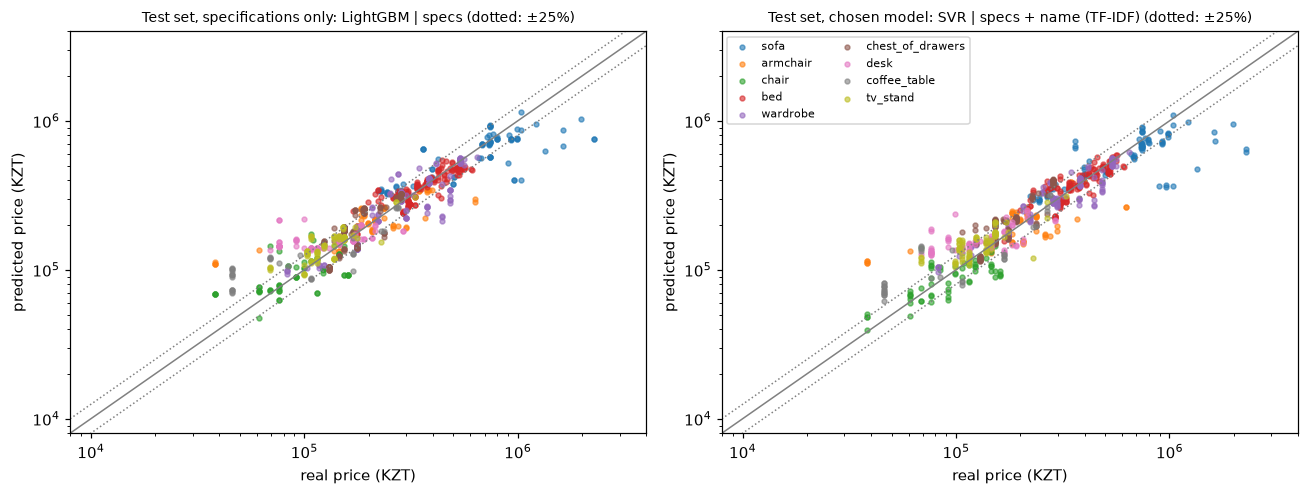

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, n, title in [(axes[0], PRICE_SPECS_BEST, "specifications only"), (axes[1], PRICE_BEST, "chosen model")]:
    for t in TYPES:
        m = ptest["furniture_type"].values == t
        ax.scatter(np.exp(py_test[m]), np.exp(PRICE_TEST[n][m]), s=10, alpha=0.6, label=t)
    lim = [8e3, 4e6]
    ax.plot(lim, lim, color="grey", lw=1); ax.plot(lim, [l * 1.25 for l in lim], ls=":", color="grey", lw=1); ax.plot(lim, [l * 0.8 for l in lim], ls=":", color="grey", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("real price (KZT)"); ax.set_ylabel("predicted price (KZT)")
    ax.set_title(f"Test set, {title}: {n} (dotted: ±25%)", fontsize=9)
axes[1].legend(fontsize=7, ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

In [40]:
# The largest test errors of the chosen model (names shown only to explain the errors)
res.assign(abs_err=(res["chosen"] - res["price_kzt"]).abs()).sort_values("abs_err", ascending=False).drop(columns="abs_err").head(12)

,name,furniture_type,width_cm,depth_cm,height_cm,materials,price_kzt,specs only,chosen,"error, chosen (%)"
253,Диван модульный Нолан 5 Шенилл Светло-серый,sofa,243.0,243.0,77.0,metal|plywood,2284860.0,757100.0,617900.0,-73.0
255,Диван модульный Нолан 5 Шенилл Зеленый,sofa,243.0,243.0,77.0,metal|plywood,2284860.0,756600.0,652300.0,-71.0
1984,Диван модульный Риббл 6 Букле Мятный,sofa,324.0,238.0,72.0,chipboard|fibreboard|plywood|solid_wood,1974870.0,1023100.0,946500.0,-52.0
243,Диван модульный Нолан 4 Шенилл Латте,sofa,243.0,161.0,77.0,metal|plywood,1626520.0,675400.0,731300.0,-55.0
235,Диван модульный Нолан 3 Шенилл Белый,sofa,243.0,81.0,77.0,metal|plywood,1347230.0,624800.0,477400.0,-65.0
1985,Диван модульный Риббл 7 Букле Мятный,sofa,271.0,176.0,72.0,chipboard|fibreboard|plywood|solid_wood,1622690.0,865400.0,845800.0,-48.0
231,Диван модульный Нолан 2 Шенилл Синий,sofa,162.0,81.0,77.0,metal|plywood,1037160.0,399700.0,364400.0,-65.0
224,Диван модульный Нолан 1 Шенилл Синий,sofa,162.0,81.0,77.0,metal|plywood,964510.0,399700.0,361200.0,-63.0
225,Диван модульный Нолан 1 Шенилл Светло-серый,sofa,162.0,81.0,77.0,metal|plywood,964510.0,400600.0,371000.0,-62.0
94,Диван прямой Брера Велюр Красный,sofa,230.0,88.0,75.0,chipboard|fibreboard|plywood|solid_wood,895680.0,525200.0,364600.0,-59.0


In [41]:
# What the name carries that the specifications do not: words with the largest weight in the ridge model on the
# MASKED name (so the design names are gone). Weights are on log price: +0.10 is about +10% price.
rm = PRICE_FIT["ridge | specs + masked name (TF-IDF)"]
ct = rm.named_steps["prep"]
words = ct.named_transformers_["text"].transformer_list[0][1]
n_spec = ct.named_transformers_["specs"].transform(ptrain.head(1)[SPECS]).shape[1]
coef = pd.Series(rm.named_steps["model"].coef_[n_spec:n_spec + len(words.vocabulary_)], index=words.get_feature_names_out())
pd.concat({"raise the price": coef.sort_values(ascending=False).head(15).round(3).reset_index().set_axis(["word", "weight"], axis=1),
           "lower the price": coef.sort_values().head(15).round(3).reset_index().set_axis(["word", "weight"], axis=1)}, axis=1)

raise the price             lower the price       
               word weight                 word weight
0      комод модель  0.168  модель терракотовый -0.240
1             комод  0.153         модель латте -0.113
2       модель мини  0.116          стул модель -0.106
3              мини  0.116                 стул -0.106
4      зеленый орех  0.110                белый -0.099
5   детская кровать  0.108         модель 93x85 -0.095
6          90 велюр  0.106                93x85 -0.095
7               мех  0.101        модель 120x52 -0.094
8         шкаф купе  0.098               120x52 -0.094
9              купе  0.098      тумба подвесная -0.093
10      купе модель  0.098     подвесная модель -0.093
11             орех  0.096            подвесная -0.093
12          офисная  0.095                  дуб -0.091
13    офисная тумба  0.095               зеркал -0.090
14           183x60  0.093                  без -0.090

In [42]:
# Do the words fix the errors of the specifications? Mean signed error in log price (+0.10 = about 10% too high)
# for test listings whose name contains each word, before and after adding the name.
KEYS = {"velour (велюр)": "велюр", "chenille (шенилл)": "шенилл", "eco-leather (экокожа)": "экокож", "rogozhka (рогожка)": "рогожк",
        "boucle (букле)": "букле", "corner (угловой)": "углов", "modular (модульный)": "модульн", "recliner (реклайнер)": "реклайн",
        "with lift (с подъемным)": "подъем", "children's (детск-)": "детск", "oak (дуб)": "дуб", "white (белый)": "белый"}
low = ptest["name"].str.lower()
rows = []
for label, k in KEYS.items():
    m = low.str.contains(k).values
    if m.sum() >= 5:
        rows.append({"word in name": label, "test listings": int(m.sum()),
                     "bias, specs only": (PRICE_TEST[PRICE_SPECS_BEST][m] - py_test[m]).mean(),
                     "bias, chosen": (PRICE_TEST[PRICE_BEST][m] - py_test[m]).mean(),
                     "MAPE specs only": np.mean(np.abs(np.exp(PRICE_TEST[PRICE_SPECS_BEST][m] - py_test[m]) - 1)),
                     "MAPE chosen": np.mean(np.abs(np.exp(PRICE_TEST[PRICE_BEST][m] - py_test[m]) - 1))})
pd.DataFrame(rows).set_index("word in name").round(3)

,test listings,"bias, specs only","bias, chosen",MAPE specs only,MAPE chosen
word in name,,,,,
velour (велюр),171,0.032,-0.018,0.134,0.150
chenille (шенилл),20,-0.431,-0.449,0.322,0.326
rogozhka (рогожка),70,0.018,-0.006,0.191,0.192
boucle (букле),42,-0.118,-0.018,0.144,0.140
corner (угловой),20,0.041,0.060,0.231,0.223
modular (модульный),13,-0.628,-0.677,0.430,0.464
children's (детск-),18,-0.139,-0.172,0.168,0.154
oak (дуб),16,0.121,0.104,0.319,0.267
white (белый),104,0.047,0.076,0.244,0.225


**What the errors show**
* **The biggest errors are modular sofas** (*Нолан*, *Риббл*): sold in numbered configurations priced at 1-2.3 million KZT, and predicted at 0.36-1.0 million by both models (-48 to -73%). The listed sizes barely separate the configurations (*Нолан 1* and *Нолан 2* are both 162 × 81 cm, at 964,510 and 1,037,160 KZT), and the configuration number in the name means nothing to the model. Neither source carries what sets the price here.
* **Per type, the name helps most for wardrobes** (test MAE 48,400 → 30,900 KZT against LightGBM on specifications: "шкаф-купе", sliding doors, costs more than a hinged wardrobe of the same size). For coffee tables, beds and chairs the change is small (1-4%).
* **It hurts armchairs** (40,400 → 47,400 KZT), **TV stands** (20,800 → 24,900) and **chests of drawers** (36,800 → 39,100). For chests, almost all of the error is one design: the wide *Монблан* chest (185 × 50 × 76 cm) appears **16 times** in the test set (four front patterns × four colours, all 283,200 KZT), and the name model prices every copy about 40% too high. Counted per design, it is one error. Section 1.5 already showed this effect for the type. (Against the forest, the name had *helped* TV stands, 32,000 → 24,900: LightGBM already prices them well from the sizes.)
* **Words the model learned** (ridge on the masked name, weights on log price): raise the price: *мех* (faux fur), *велюр*, *орех* (walnut), *шкаф-купе*, *офисная*, *детская кровать*, *мини*; lower the price: *подвесная* (wall-hung), *белый*, *дуб* (an oak-effect board colour), *стул*. These are exactly the things the specification table does not record.
* **Fabric:** for boucle (*букле*) the specifications under-price by 11% on average and the name removes that bias (-0.118 → -0.018 in log price). For chenille (*шенилл*, mostly the modular sofas) and modular sofas the bias stays large (-0.45 and -0.68).
* **What would help next:** the configuration of modular sets, the number of seats, the mechanism (recliner, lift, sofa-bed), the brand line, and photos. The photos are not allowed (section 3); the rest could be parsed from the specification table, which we did not do for the Final.

### 7.4 Does the name help in another market? IKEA Saudi Arabia (added after the survey)

> **In plain words.** Everything above is one store in one city. If "the product name adds what the specifications miss" is a real pattern and not a mebel.kz accident, it should also hold elsewhere. **IKEA Saudi Arabia** (620 items of our types with all three sizes, prices in Saudi riyals, scraped from ikea.com/sa in April 2020; rights in section 3.2) is a very different store: one brand, flat-pack furniture, English labels such as *"HEMNES Chest of 8 drawers, 160x96 cm"*.
> * **Specifications:** the sizes (height, longer and shorter side, footprint, volume, two ratios, on a log scale) and the type. IKEA lists **no materials or colour**, so its specifications are poorer than mebel.kz's.
> * **Text:** product line name + short description, read with **the same TF-IDF features** as the mebel.kz names (`furniture/price.py: tfidf`).
> * **Protocol:** grouped 5-fold CV, one group per product line (all HEMNES items together), stratified by type, seed 42, settings tuned on the same folds. 620 items are too few for a separate test set, so CV only, as for ABO.

In [43]:
from furniture.ikea import load_ikea_sa, ikea_pipe
isa = load_ikea_sa()
iy = np.log(isa["price_sar"].values)
ISPLITS = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(isa, isa["furniture_type"], isa["group"]))
print(f"IKEA SA: {len(isa)} items in {isa['group'].nunique()} product lines | median price {isa['price_sar'].median():,.0f} SAR "
      f"(range {isa['price_sar'].min():,.0f} - {isa['price_sar'].max():,.0f})")
LGB_SMALL = {"model__learning_rate": [0.03, 0.06], "model__num_leaves": [7, 15], "model__min_child_samples": [5, 15]}
IKEA_MODELS = {
    "ridge | specs": ("specs", ikea_pipe(Ridge()), {"model__alpha": [0.3, 1, 3, 10]}),
    "random forest | specs": ("specs", ikea_pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                              {"model__min_samples_leaf": [1, 3, 10]}),
    "LightGBM | specs": ("specs", ikea_pipe(LGBMRegressor(n_estimators=400, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)), LGB_SMALL),
    "SVR | specs": ("specs", ikea_pipe(SVR()), SVR_GRID),
    "ridge | specs + name (TF-IDF)": ("specs + name", ikea_pipe(Ridge(), text=True), {"model__alpha": [0.3, 1, 3, 10]}),
    "SVR | specs + name (TF-IDF)": ("specs + name", ikea_pipe(SVR(), text=True), SVR_GRID),
}
isa_med = np.zeros(len(isa))
for tr, va in ISPLITS:
    isa_med[va] = isa.iloc[va]["furniture_type"].map(pd.Series(iy[tr]).groupby(isa.iloc[tr]["furniture_type"].values).median()).values
irow, IOOF = [], {"median price of the type": isa_med}
for name, (inputs, p, grid) in IKEA_MODELS.items():
    s = GridSearchCV(p, grid, cv=ISPLITS, scoring="neg_mean_absolute_error", n_jobs=1 if "forest" in name else -1).fit(isa, iy)
    IOOF[name] = cross_val_predict(clone(s.best_estimator_), isa, iy, cv=ISPLITS)
ifold = lambda o: np.array([np.mean(np.abs(np.exp(o[va]) - np.exp(iy[va]))) for _, va in ISPLITS])
ikea_price = pd.DataFrame({n: {"inputs": IKEA_MODELS[n][0] if n in IKEA_MODELS else "type",
                               "CV MAE (SAR)": price_metrics(iy, o)["MAE (KZT)"],   # price_metrics names the unit KZT; here it is SAR
                               "CV fold sd": ifold(o).std(), "CV MAPE": price_metrics(iy, o)["MAPE"],
                               "CV R² (log)": price_metrics(iy, o)["R² (log)"]} for n, o in IOOF.items()}).T
ikea_price.style.format({"CV MAE (SAR)": "{:,.0f}", "CV fold sd": "{:,.0f}", "CV MAPE": "{:.3f}", "CV R² (log)": "{:.3f}"})

IKEA SA: 620 items in 147 product lines | median price 1,295 SAR (range 40 - 9,585)


,inputs,CV MAE (SAR),CV fold sd,CV MAPE,CV R² (log)
median price of the type,type,"1,004",238,0.827,0.453
ridge | specs,specs,683,181,0.466,0.766
random forest | specs,specs,714,220,0.473,0.730
LightGBM | specs,specs,720,241,0.476,0.732
SVR | specs,specs,695,196,0.466,0.767
ridge | specs + name (TF-IDF),specs + name,660,234,0.431,0.757
SVR | specs + name (TF-IDF),specs + name,637,245,0.399,0.781


In [44]:
# Paired: the same five folds, fold MAE of each specs + name model minus the best specifications-only model
I_SPECS_BEST = min([n for n in IKEA_MODELS if IKEA_MODELS[n][0] == "specs"], key=lambda n: ikea_price.at[n, "CV MAE (SAR)"])
print("best specifications-only model on IKEA SA:", I_SPECS_BEST)
pd.DataFrame({n: {"mean change in fold MAE (SAR)": (ifold(IOOF[n]) - ifold(IOOF[I_SPECS_BEST])).mean(),
                  "sd of the change": (ifold(IOOF[n]) - ifold(IOOF[I_SPECS_BEST])).std(),
                  "folds better": int(((ifold(IOOF[n]) - ifold(IOOF[I_SPECS_BEST])) < 0).sum()),
                  "change in MAPE": price_metrics(iy, IOOF[n])["MAPE"] - price_metrics(iy, IOOF[I_SPECS_BEST])["MAPE"]}
              for n in IKEA_MODELS if IKEA_MODELS[n][0] == "specs + name"}).T.round(3)

best specifications-only model on IKEA SA: ridge | specs


,mean change in fold MAE (SAR),sd of the change,folds better,change in MAPE
ridge | specs + name (TF-IDF),-54.830,120.146,3.0,-0.035
SVR | specs + name (TF-IDF),-73.104,104.631,4.0,-0.067


**What the second market shows** (620 IKEA items, 147 product lines, grouped 5-fold CV)
* **The text helps here too.** SVR on sizes + type + product text: CV MAE **637 SAR, MAPE 39.9%**, against **683 SAR, MAPE 46.6%** for the best specifications-only model (ridge). The median price of the type: 1,004 SAR, MAPE 82.7%. The SVR wins in 4 of 5 folds (-73 ± 105 SAR per fold), ridge with text in 3 of 5.
* **The same model family wins in both stores:** SVR on specifications + TF-IDF text is the best model at mebel.kz (section 7) and at IKEA, with the same text features and no change to them. On IKEA, the trees (forest 714, LightGBM 720) are slightly *worse* than the linear model: with 620 items and no materials, there is not enough data for them.
* **Errors are much larger than at mebel.kz (MAPE 40% vs 23%)** because IKEA's specifications are poorer: no materials, no colour, and a wardrobe "combination" or a corner sofa can have the same outer size at very different prices. This is the same lesson as 7.3: the price lives in what the size table does not say.
* **Limits:** prices are from one day in April 2020, in another currency and market, so IKEA numbers are compared only *inside* IKEA, never with mebel.kz in KZT. 620 items give a noisy CV (fold sd 180-245 SAR), so the result supports the mebel.kz finding but does not measure it precisely.

## 8. Saving the models for the app

> **In plain words.** The app (`api.py` + `frontend/`, run with `.venv/bin/python api.py`; the older Streamlit `app.py` still works for the type models) needs fitted models. We fit each chosen model once more on all its training data, with the settings the cross-validation picked, and save it with everything the app needs to rebuild the inputs.

In [45]:
import ast, joblib
from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from furniture.abo import spec_prep as abo_spec_prep
from furniture.photos import cached_resnet18_features

chosen = ast.literal_eval(z["chosen"].item())
most_common = lambda name: dict(Counter(tuple(sorted(p.items())) for p in chosen[name]).most_common(1)[0][0])

# 1) specifications, mebel.kz: the model chosen in section 1.6, with probabilities for the app
structured = pipe(clone(TUNED[BEST]["model"]).set_params(probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)
joblib.dump({"pipeline": structured, "features": FEATURES, "materials": MATERIALS, "name": f"{BEST} (mebel.kz)",
             "cv_macro_f1": float(TUNED[BEST]["folds"].mean()), "sklearn": sklearn.__version__}, "models/structured_best.joblib")

# 2) and 3) photo, and photo + specifications, ABO: fitted on every ABO listing with a photo
feats = cached_resnet18_features(views["image_id"], views["path"])
EMB = [f"r{i}" for i in range(feats.shape[1])]
emb = pd.DataFrame(feats, columns=EMB).groupby(views["row"].values).mean()
abo_fit = pd.concat([abo.loc[emb.index].reset_index(drop=True), emb.reset_index(drop=True)], axis=1)
SPEC_NUM = SIZE + WEIGHT
photo_pipe = SkPipeline([("scale", ColumnTransformer([("r", StandardScaler(), EMB)])),
                         ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
photo_pipe.set_params(**most_common("photo (ResNet-18 + logistic regression)")).fit(abo_fit, abo_fit["furniture_type"])
both_pipe = SkPipeline([("prep", ColumnTransformer([("spec", abo_spec_prep(SPEC_NUM), SPEC_NUM + ABO_MATERIALS + ["main_color"]),
                                                    ("r", StandardScaler(), EMB)])),
                        ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
both_pipe.set_params(**most_common("specs + photo (logistic regression)")).fit(abo_fit, abo_fit["furniture_type"])
for path, p, name in [("models/abo_photo.joblib", photo_pipe, "photo (ResNet-18 + logistic regression)"),
                      ("models/abo_specs_photo.joblib", both_pipe, "specs + photo (logistic regression)")]:
    joblib.dump({"pipeline": p, "embedding_columns": EMB, "name": name, "settings": p.get_params()["model__C"],
                 "cv_macro_f1": float(abo_summary.loc[name, "CV macro-F1"]), "sklearn": sklearn.__version__}, path)

# reload check: the saved files give the same predictions
assert (joblib.load("models/structured_best.joblib")["pipeline"].predict(X_test) == structured.predict(X_test)).all()
assert (joblib.load("models/abo_photo.joblib")["pipeline"].predict(abo_fit) == photo_pipe.predict(abo_fit)).all()
print("saved: structured", BEST, "| photo C =", photo_pipe.get_params()["model__C"], "| specs + photo C =", both_pipe.get_params()["model__C"])

saved: structured SVM | photo C = 0.003 | specs + photo C = 0.01


In [46]:
# 1b) type WITHOUT the price (added after a user test of the app: "the type should not need a price").
#     Same SVM recipe and grouped folds as section 1.6, inputs: sizes, the derived sizes, materials and colour.
from sklearn.preprocessing import OneHotEncoder
NOPRICE_NUM = [c for c in NUMERIC if "price" not in c]
noprice_pipe = lambda m: SkPipeline([("prep", ColumnTransformer([
    ("numeric", StandardScaler(), NOPRICE_NUM), ("materials", "passthrough", MATERIALS),
    ("colour", OneHotEncoder(handle_unknown="ignore", min_frequency=10), COLOUR)])), ("model", m)])
s_np = GridSearchCV(noprice_pipe(SVC(class_weight="balanced")), {"model__C": [1, 3, 10, 30], "model__gamma": ["scale", 0.03, 0.1, 0.3]},
                    cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train, groups=g_train)
np_folds = cross_validate(clone(s_np.best_estimator_), X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro")["test_score"]
noprice = noprice_pipe(clone(s_np.best_estimator_.named_steps["model"]).set_params(probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)
np_pred = noprice.predict(X_test)
print(f"type without price, SVM {s_np.best_params_}: CV macro-F1 {np_folds.mean():.3f} ± {np_folds.std():.3f} | "
      f"test {f1_score(y_test, np_pred, average='macro'):.3f} | with price (chosen SVM): CV {TUNED[BEST]['folds'].mean():.3f}")
joblib.dump({"pipeline": noprice, "features": NOPRICE_NUM + MATERIALS + COLOUR, "materials": MATERIALS,
             "name": "SVM without price (mebel.kz)", "cv_macro_f1": float(np_folds.mean()), "sklearn": sklearn.__version__},
            "models/structured_noprice.joblib")
assert (joblib.load("models/structured_noprice.joblib")["pipeline"].predict(X_test) == np_pred).all()
pd.Series(f1_score(y_test, np_pred, average=None, labels=TYPES), index=TYPES, name="test F1 without price").round(3).to_frame().T

type without price, SVM {'model__C': 10, 'model__gamma': 0.1}: CV macro-F1 0.950 ± 0.021 | test 0.971 | with price (chosen SVM): CV 0.949


,sofa,armchair,chair,bed,wardrobe,chest_of_drawers,desk,coffee_table,tv_stand
test F1 without price,0.971,0.971,1.0,0.989,0.989,0.953,0.906,1.0,0.963


**Type without the price.** A tester of the app pointed out that the type form required a price, although a type should be readable from the item itself. Re-tuned on the same grouped folds without the two price inputs, the SVM (C = 10, gamma = 0.1) scores **CV macro-F1 0.950 ± 0.021 and test 0.971**, the same as the chosen SVM with the price (0.949; test 0.974). **The price adds nothing to the type** once sizes and materials are known, which fits section 4.1: the type is a question of size and materials. The app now uses this model when no price is entered (`models/structured_noprice.joblib`). We keep the chosen model of section 1.6 for the comparison above, because that choice was made before this check.

In [47]:
# 2b) and 3b) the stronger photo encoder of section 5.6 (DINOv2, frozen), same recipe: fitted on every ABO listing
#     with a photo, C = the value chosen most often in the five outer folds
from furniture.photos import cached_features
chosen2 = ast.literal_eval(z2["chosen"].item())
dfeats = cached_features("dinov2", views["image_id"], views["path"])
DEMB = [f"dinov2_{i}" for i in range(dfeats.shape[1])]
demb = pd.DataFrame(dfeats, columns=DEMB).groupby(views["row"].values).mean()
abo_fit2 = pd.concat([abo.loc[demb.index].reset_index(drop=True), demb.reset_index(drop=True)], axis=1)
dphoto = SkPipeline([("scale", ColumnTransformer([("e", StandardScaler(), DEMB)])),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
dboth = SkPipeline([("prep", ColumnTransformer([("spec", abo_spec_prep(SPEC_NUM), SPEC_NUM + ABO_MATERIALS + ["main_color"]),
                                                ("e", StandardScaler(), DEMB)])),
                    ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
for path, p, name in [("models/abo_photo_dinov2.joblib", dphoto, "photo (DINOv2 + logistic regression)"),
                      ("models/abo_specs_photo_dinov2.joblib", dboth, "specs + photo (DINOv2, logistic regression)")]:
    p.set_params(model__C=Counter(chosen2[name]).most_common(1)[0][0]).fit(abo_fit2, abo_fit2["furniture_type"])
    joblib.dump({"pipeline": p, "embedding_columns": DEMB, "encoder": "dinov2", "name": name, "settings": p.get_params()["model__C"],
                 "cv_macro_f1": float(abo_all.loc[name, "CV macro-F1"]), "sklearn": sklearn.__version__}, path)
    assert (joblib.load(path)["pipeline"].predict(abo_fit2) == p.predict(abo_fit2)).all()
    print("saved", path, "| C =", p.get_params()["model__C"], "| CV macro-F1", round(abo_all.loc[name, "CV macro-F1"], 3))

saved models/abo_photo_dinov2.joblib | C = 0.01 | CV macro-F1 0.844


saved models/abo_specs_photo_dinov2.joblib | C = 0.1 | CV macro-F1 0.851


In [48]:
# 4) price, mebel.kz: the best specifications-only model and the best specifications + name model (section 7),
#    fitted on the 2,971 training listings. The range shown in the app is the 10th-90th percentile of the
#    cross-validated errors in log price.
def price_entry(n):
    resid = py_train - PRICE_OOF[n]
    entry = {"pipeline": PRICE_FIT[n], "name": n, "cv_mae_kzt": float(price_table.at[n, "CV MAE (KZT)"]),
             "cv_mape": float(price_table.at[n, "CV MAPE"]), "residual_q10": float(np.quantile(resid, 0.1)),
             "residual_q90": float(np.quantile(resid, 0.9))}
    if "(e5)" in n:
        entry.update(e5_columns=E5_COLS["text"], e5_model=E5_MODEL)
    return entry

joblib.dump({"specs": price_entry(PRICE_SPECS_BEST), "with_name": price_entry(PRICE_NAME_BEST), "materials": MATERIALS,
             "material_names": [m[len("mat_"):] for m in MATERIALS], "colours": sorted(df["main_color"].unique()),
             "sklearn": sklearn.__version__}, "models/price_best.joblib")
saved_price = joblib.load("models/price_best.joblib")
assert np.allclose(saved_price["with_name"]["pipeline"].predict(ptest), PRICE_TEST[PRICE_NAME_BEST])
assert np.allclose(saved_price["specs"]["pipeline"].predict(ptest), PRICE_TEST[PRICE_SPECS_BEST])
for k in ["specs", "with_name"]:
    e = saved_price[k]
    print(f"{k}: {e['name']} | CV MAE {e['cv_mae_kzt']:,.0f} KZT | in CV, 80% of real prices were between "
          f"{100 * (np.exp(e['residual_q10']) - 1):+.0f}% and {100 * (np.exp(e['residual_q90']) - 1):+.0f}% of the prediction")

specs: LightGBM | specs | CV MAE 60,591 KZT | in CV, 80% of real prices were between -33% and +51% of the prediction
with_name: SVR | specs + name (TF-IDF) | CV MAE 59,071 KZT | in CV, 80% of real prices were between -31% and +40% of the prediction


## 9. Conclusions

**Main question: the price.** On the same 3,961 mebel.kz listings, the same 793 test listings and the same design groups:
1. **Specifications predict the price to within about 25% on average** (best: LightGBM, grouped CV MAE 60,600 KZT, MAPE 25%, R² on log price 0.77; test MAE 53,700 KZT, MAPE 22%). The median price of the type is far worse (CV MAE 94,800). Linear, forest, boosting, LightGBM and kernel models are within the fold spread of each other (section 7): a stronger tree library did not move the error much.
2. **The product name adds a small but steady improvement.** SVR on specifications + TF-IDF of the name: CV MAE 59,100, test 51,700 KZT (-3.6% against LightGBM), MAPE 20.6%. It wins in all six fold cuts we tried, by 1,500-4,300 KZT (section 7.2).
3. **The same holds in a second market.** On 620 IKEA Saudi Arabia items, the same SVR + TF-IDF text beats the best specifications-only model (MAPE 46.6% → 39.9%, 4 of 5 folds) (section 7.4).
4. **Our own text features beat the pretrained encoder.** multilingual-e5-small adds less than TF-IDF in CV and nothing on the test set: the names are short and full of shop-specific words and sizes.
5. **The text is not memorising design prices.** With the design name masked, three quarters of the SVR's gain over specifications remains; it comes from words like fabric (*букле*, *велюр*, *мех*), sliding doors (*шкаф-купе*), wall-hung (*подвесная*) (section 7.1, 7.3).
6. **What neither source carries:** the configuration of modular sofas and brand-line premiums; the largest errors (-48 to -73%) are modular sets of 1-2.3 million KZT.

**Findings on the type (sections 1-6)**
7. **The type is a size question.** Three sizes alone give test macro-F1 0.918; all inputs give about 0.95 in grouped CV (SVM 0.949 ± 0.019, ± 0.003 between fold cuts). Part of the Endterm's 0.97 and its model ranking came from colour twins across the split (section 1).
8. **The weak classes are the mid-size case furniture** (TV stand, desk, chest: CV F1 0.875-0.914), not the small coffee-table class (PR-AUC 0.991) (section 2).
9. **The type model is a one-store model:** 0.606 on Amazon listings with sizes only (section 6).
10. **Photos help where the sizes fail**, tested on Amazon (other products, CC BY 4.0): a frozen ResNet-18 beats the specifications (0.766 vs 0.662); a small CNN trained from scratch does not (0.605) (section 5).
11. **A better pretrained encoder matters more than training more of a weak one.** Frozen DINOv2 reaches 0.844 (0.851 with specs, TV-stand recall 0.08 → 0.78), CLIP 0.801, while fine-tuning ResNet-18 gives 0.789 for 50 minutes of CPU. On 221 IKEA photos never seen in training, DINOv2 also transfers best (macro-F1 0.880 vs 0.755 for ResNet-18) (sections 5.6-5.7).

**Limitations**
* One store, one city, prices from one day in October 2026 (with any discount of that day). The price models will not transfer as they are to other stores or later prices.
* The second source on the same listings is text, not photos: the store's copyright notice forbids reusing its photos (section 3). The photo results therefore come from other products (ABO) and test the type, not the price (ABO has no price).
* Tuning and CV used the same folds, so CV numbers are slightly optimistic; the test set (92 designs) is small, and one design in many colours can dominate a class (the *Монблан* chest, 16 test listings).
* The pretrained text encoder was used frozen and in its small size; fine-tuning or a larger model might narrow the gap to TF-IDF.
* Amazon's rare classes are very small (21 TV-stand, 39 chest, 49 wardrobe products); their per-class numbers can move by 0.1 with a few products. The small CNN underfits (CPU, 15 epochs, 64 px); the fine-tuned ResNet-18 trained only 3 epochs at 160 px on two photos per listing (CPU time).
* The IKEA sources are weaker evidence than ABO: IKEA SA has no stated licence (used as facts, like mebel.kz) and is one day in 2020 in another currency; the IKEA photos are the dataset authors' non-commercial permission, not IKEA's, and only 221 can be labelled. Both are used only to check whether the mebel.kz and ABO findings hold elsewhere.
* Labels in both stores are the stores' own categories; some listings sit at the border (an office pedestal filed as a desk, low cabinets among chests).